# Milestone 3: baseline models, leakage-free cross-validation and error-cost analysis

**Trans-Boundary Smog Prediction: Crop Fires and Climate Traps across Punjab (Pakistan and India)**
Munir Tariq (10067), Ismail Nooruddin (09958), Bilal Ayub (09716)

This notebook builds and evaluates the Milestone 3 baselines for the headline target `target_spike_h1`
(is tomorrow a smog spike in this city?). It reads only two files made by `merge_analysis.ipynb`:
`Dataset/clean/master_daily.parquet` and `Dataset/clean/role2_params.json`.
All modelling code lives in `src/modeling.py` (data access, feature sets, CV splitter, pipelines,
tuning, thresholds) and `src/evaluate.py` (metrics, block bootstrap, cost curve, error breakdown).

| Section | What it does |
|---|---|
| M3.1 | Load, leakage guards, class balance per split |
| M3.2 | Purged, repeated StratifiedGroupKFold (25 folds) |
| M3.3 | Naive benchmarks; tuning of logistic regression (LR) and decision tree (DT) on 3 feature sets; leakage check (random stratified vs grouped vs purged CV) |
| M3.4 | Cross-validated and validation metrics with block-bootstrap CIs |
| M3.5 | Fire ablation: do fires add skill? |
| M3.6 | Asymmetric error cost (FN:FP = 5:1 headline, curve 1 to 20) |
| M3.7 | Confusion matrices, edge cases and a preliminary disparity check (error rates by country and city) |
| M3.8 | Drivers: odds ratios, the H2 weather-trap test, Gini and permutation importance |
| M3.9 | Sensitivity: (a) month-wise spike label; (b) horizons h = 2 and 3; (c) raw-index AQ encoding; (d) regression of the continuous index (Ridge) |
| M3.10 | Saved model artifacts and package versions |

**Run:** from the repository root, Kernel > Restart and Run All
(or `jupyter nbconvert --to notebook --execute --inplace modeling.ipynb`). All seeds are fixed, so a rerun
writes byte-identical tables to `docs/tables/m3_*.csv`.

**Rules kept from Milestone 2:** 2024 is sealed (asserted below); every fit, scaler, threshold and
hyperparameter choice uses `split == "train"` only (2022-08-04 to 2023-08-31); the validation split
(2023-09-04 to 2023-12-31) is used only to report results.

In [1]:
# ------------------------------------------------------------
# Setup: imports, paths and settings
# ------------------------------------------------------------
import json
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D

ROOT = Path.cwd()                          # run from the repository root
sys.path.append(str(ROOT))

from src import config as C                # shared rules: cities, dates, folders
from src import modeling as MD             # data access, CV, pipelines, tuning, thresholds
from src import evaluate as EV             # metrics, bootstrap, cost curve, error breakdown
from src import plotting as P              # one figure style for every figure
from src.evaluate import save_table

P.set_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
T0 = time.time()

H = 1                                      # headline horizon: tomorrow
TARGET = f"target_spike_h{H}"
COST_FN, COST_FP = EV.COST_FN, EV.COST_FP  # 5:1 (decision D6)
N_BOOT = 1000

role2 = json.loads((C.CLEAN_DIR / "role2_params.json").read_text())
assert role2["fire_setting"]["tag"] == "up45_r300", "fire features must use the Milestone 2 setting"
print("Fire setting from Milestone 2:", role2["fire_setting"]["tag"], "-", role2["fire_setting"]["rule"])

# Model names, labels and fixed colours (colour = feature set, line style = model family)
SETS = list(MD.FEATURE_SETS)                                   # full, weather_only, no_fire
SET_LABEL = {"full": "full", "weather_only": "weather-only", "no_fire": "no-fire"}
SET_COLOR = {"full": P.CAT_COLORS[0], "weather_only": P.CAT_COLORS[1], "no_fire": P.CAT_COLORS[2]}
MODELS = ["majority", "persistence"] + [f"{f}_{s}" for f in ("lr", "dt") for s in SETS]
LABEL = {"majority": "Majority class", "persistence": "Persistence",
         **{f"{f}_{s}": f"{f.upper()} {SET_LABEL[s]}" for f in ("lr", "dt") for s in SETS}}
COLOR = {"majority": P.GREY, "persistence": "#000000",
         **{f"{f}_{s}": SET_COLOR[s] for f in ("lr", "dt") for s in SETS}}
STYLE = {m: ("--" if m.startswith("dt") else "-") for m in MODELS}

Fire setting from Milestone 2: up45_r300 - highest median Spearman rho (fire day t vs index day t+1) over the 7 Pakistani cities, training Oct-Dec


---
## M3.1 Data and leakage guards

`MD.load_model_frame()` reads the master table, asserts that no date reaches 2024, and drops (decision D12):
the 3-day skip between train and validation, rows with a missing target (the last day of 2023) or feature
(the first two days of each city lack `index_lag2`), and rows whose **feature day or target day** is one of the
44 `suspect_day` rows (13 to 16 December 2022, near-zero pollutant values in every city). Those rows stay in the
master (the daily calendar needs them) but never enter a fit or a score. The validation split has no suspect days.

**AQ history as a margin over the city threshold.** The loader also adds `persist_margin`, `margin_lag1` and
`margin_lag2` = the index on day t, t − 1 and t − 2 **minus the city's spike threshold** (0.36 for Rahim Yar Khan up
to 2.18 for Lahore, learned on training October to March days in Milestone 2). The spike label is defined relative
to that threshold, so the raw pooled index made the city dummies act as a threshold correction. The margins are the
headline AQ-history encoding; this was fixed before any result was seen. The raw-index version is retuned as a
sensitivity run in M3.9c. A margin of 0 or more on day t is exactly `persist_spike = 1` (asserted in the loader).

In [2]:
df, drop_log = MD.load_model_frame(H)
print("Rows dropped before modelling, by reason and split:")
print(drop_log.to_string())

train = df[df["split"] == "train"].reset_index(drop=True)
val = df[df["split"] == "validation"].reset_index(drop=True)
y_tr, y_va = train[TARGET].to_numpy(), val[TARGET].to_numpy()

# Leakage guards: the two parts are chronological and disjoint, and nothing reaches 2024
assert train["date"].max() <= pd.Timestamp(C.TRAIN_END) < pd.Timestamp(C.VALID_START) <= val["date"].min()
assert val["date"].max() < MD.SEALED_FROM and df["date"].max() < MD.SEALED_FROM
assert set(df["split"]) == {"train", "validation"}


def assert_train_only(frame):
    """Called before every fit: only training-period rows may reach a model."""
    assert frame["date"].max() <= pd.Timestamp(C.TRAIN_END), "a validation row reached a fit"
    assert (frame["split"] == "train").all()


balance = pd.DataFrame({
    s: {"first day": d["date"].min().date(), "last day": d["date"].max().date(),
        "city-days": len(d), "share of rows (%)": 100 * len(d) / len(df),
        "spikes": int(d[TARGET].sum()), "spike rate (%)": 100 * d[TARGET].mean(),
        "suspect rows dropped": int(drop_log.loc[["suspect feature day", "suspect target day"], s].sum())
        if s in drop_log.columns else 0}
    for s, d in [("train", train), ("validation", val)]}).T
balance.index.name = "split"
print()
print(balance.to_string())
_ = save_table(balance, "m3_split_balance")

Rows dropped before modelling, by reason and split:
split                skip  validation  train
dropped because                             
skip split             33           0      0
missing target          0          11      0
missing feature         0           0     22
suspect feature day     0           0     44
suspect target day      0           0     11

             first day    last day city-days share of rows (%) spikes spike rate (%) suspect rows dropped
split                                                                                                    
train       2022-08-06  2023-08-31      4246         76.587302    204       4.804522                   55
validation  2023-09-04  2023-12-30      1298         23.412698     89       6.856703                    0


**What we found (M3.1).**
- **Rows.** After the D12 drops, training has **4,246 city-days** (2022-08-06 to 2023-08-31) with **204 spikes (4.80%)**, and validation has **1,298 city-days** (2023-09-04 to 2023-12-30) with **89 spikes (6.86%)**, a 76.6 / 23.4 split.
- **Drops.** 33 skip rows, 11 validation rows without a target (31 December), and 22 training rows without `index_lag2` (the first two days of each city). Another 55 training rows were dropped because of suspect days: 44 rows whose feature day is a suspect day, and 11 rows (12 December 2022) whose target day is one.
- **Class balance.** The validation spike rate is 1.4 points higher than in training. All validation spikes fall in November and December, while training also contains six spike-free months (March to August).

**Why not a random 80/20 split with stratification?** Neighbouring days are almost copies of each other
(today's index has Spearman ρ = 0.82 with tomorrow's), Islamabad and Rawalpindi share one CAMS grid cell, and the
11 cities share the same weather systems on the same day. A random split would put near-duplicates of every test
row into the training part and overstate skill. We therefore keep the **chronological** split from Milestone 2
(train ≈ 77%, validation ≈ 23% of the modelling rows) as the held-out test. Stratification is checked rather than
forced: the validation spike rate is a little higher than the training rate because validation ends in December,
the peak month, while training covers a whole year including the spike-free summer. The leakage check at the end
of M3.3 measures how much a random stratified split would overstate skill on these data.

---
## M3.2 Cross-validation design (decision D5)

Inside the training period we use **purged, repeated StratifiedGroupKFold**: k = 5 folds × 5 repeats (seeds 0 to 4)
= 25 folds.
- **Group = calendar week shared by all 11 cities.** A week is never split between the fit part and the scored
  part, so same-day copies across cities (Islamabad and Rawalpindi are identical) and near-identical neighbouring
  days cannot leak.
- **Stratified** on the spike label, so every fold has spikes (they are about 5% of rows).
- **Purge:** a training row whose target day (t + 1) falls on a held-out day is dropped from the fit part.
- **Embargo:** a training row up to 3 days after a held-out day is also dropped, because its AQ-history features
  (`persist_margin`, `margin_lag1`, `margin_lag2`, built from the index on days t to t − 2) contain the
  held-out days' target values.

Plain `StratifiedKFold` is not used for the reasons above.

In [3]:
splits = MD.purged_sgkf_splits(train, y_tr, n_splits=5, seeds=range(5), horizon=H)
weeks = MD.week_groups(train["date"])
fold_rows = []
for i, (fit_idx, test_idx) in enumerate(splits):
    assert not set(weeks[fit_idx]) & set(weeks[test_idx])          # groups disjoint
    fold_rows.append({"repeat": i // 5, "fold": i % 5, "fit rows": len(fit_idx),
                      "purged/embargoed rows": len(train) - len(test_idx) - len(fit_idx),
                      "test rows": len(test_idx), "test weeks": len(set(weeks[test_idx])),
                      "fit spike rate (%)": 100 * y_tr[fit_idx].mean(),
                      "test spike rate (%)": 100 * y_tr[test_idx].mean(), "groups disjoint": True})
folds_tab = pd.DataFrame(fold_rows)
print(folds_tab.round(2).to_string(index=False))
print("\nTest spike rate over the 25 folds: mean %.2f%%, SD %.2f%%, range %.2f to %.2f%%" % (
    folds_tab["test spike rate (%)"].mean(), folds_tab["test spike rate (%)"].std(),
    folds_tab["test spike rate (%)"].min(), folds_tab["test spike rate (%)"].max()))
_ = save_table(folds_tab, "m3_cv_folds", index=False)

 repeat  fold  fit rows  purged/embargoed rows  test rows  test weeks  fit spike rate (%)  test spike rate (%)  groups disjoint
      0     0      3025                    374        847          11                5.49                 3.78             True
      0     1      3003                    396        847          11                4.50                 4.25             True
      0     2      2992                    429        825          11                4.58                 5.58             True
      0     3      2893                    495        858          12                4.01                 6.99             True
      0     4      2937                    440        869          12                5.58                 3.45             True
      1     0      3003                    396        847          11                5.19                 3.78             True
      1     1      3003                    396        847          11                4.66               

**What we found (M3.2).** Every one of the 25 folds holds out 11 or 12 whole weeks (825 to 869 city-days). The purge and embargo remove another 286 to 495 rows from each fit part, so the cost of leakage protection is about 8% to 15% of the remaining training rows per fold. Stratification works: the test-fold spike rate averages **4.81%** (SD 1.35 points, range 3.45% to 7.08%), against 4.80% over all training rows. Week groups are disjoint in every fold (asserted in the cell above, and checked independently day by day when the module was written). The white gap in December 2022 is the dropped suspect days.

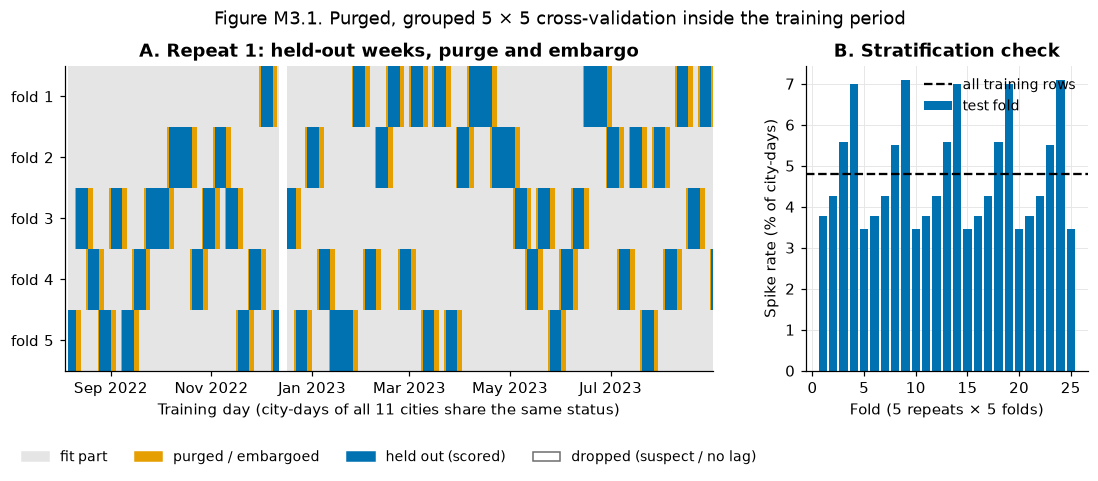

In [4]:
# Figure M3.1: fold layout of repeat 1 over the training calendar, and the spike rate of every test fold
day = (train["date"] - pd.Timestamp(C.WINDOW_START)).dt.days.to_numpy()
n_days = day.max() + 1
status = np.zeros((5, n_days))                      # 0 = fit, 1 = purged/embargoed, 2 = held out
for k, (fit_idx, test_idx) in enumerate(splits[:5]):
    status[k, :] = 1
    status[k, np.unique(day[fit_idx])] = 0
    status[k, np.unique(day[test_idx])] = 2
    present = np.zeros(n_days, bool); present[np.unique(day)] = True
    status[k, ~present] = np.nan                     # dropped suspect days

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [2.3, 1]})
cmap = ListedColormap(["#E5E5E5", P.CAT_COLORS[3], P.CAT_COLORS[0]])
cmap.set_bad("white")
ax = axes[0]
ax.imshow(status, aspect="auto", cmap=cmap, vmin=0, vmax=2, interpolation="nearest",
          extent=[0, n_days, 4.5, -0.5])
ticks = pd.date_range(C.WINDOW_START, C.TRAIN_END, freq="2MS")
ax.set_xticks([(t - pd.Timestamp(C.WINDOW_START)).days for t in ticks])
ax.set_xticklabels([t.strftime("%b %Y") for t in ticks])
ax.set_yticks(range(5)); ax.set_yticklabels([f"fold {k + 1}" for k in range(5)])
ax.grid(False)
ax.set_xlabel("Training day (city-days of all 11 cities share the same status)")
ax.set_title("A. Repeat 1: held-out weeks, purge and embargo")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in cmap.colors]
          + [plt.Rectangle((0, 0), 1, 1, facecolor="white", edgecolor=P.GREY)],
          labels=["fit part", "purged / embargoed", "held out (scored)", "dropped (suspect / no lag)"],
          loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=4)
ax = axes[1]
ax.bar(np.arange(25) + 1, folds_tab["test spike rate (%)"], color=P.CAT_COLORS[0], label="test fold")
ax.axhline(100 * y_tr.mean(), color="#000000", lw=1.5, ls="--", label="all training rows")
ax.set_xlabel("Fold (5 repeats × 5 folds)")
ax.set_ylabel("Spike rate (% of city-days)")
ax.set_title("B. Stratification check")
ax.legend(loc="upper right")
fig.suptitle("Figure M3.1. Purged, grouped 5 × 5 cross-validation inside the training period", y=1.02)
P.save(fig, "fig_m3_1_cv_folds")
plt.show()

---
## M3.3 Baselines and hyperparameter tuning

**Models (decision D4).**
1. **Majority class**: always "no spike" (`DummyClassifier("most_frequent")`). It sets the floor: accuracy is high
   only because spikes are rare.
2. **Persistence**: "tomorrow repeats today" (`persist_spike`). Its score for ranking is today's margin over the city's
   spike threshold, `persist_index − spike_threshold`, so cities with different thresholds are comparable.
   This is the benchmark any forecast must beat.
3. **Logistic regression** (L1 or L2, `liblinear`): additive, gives odds ratios a health department can read, and
   gives calibrated probabilities for an alert threshold.
4. **Decision tree**: finds non-additive "trap" rules (for example stagnant **and** humid) and can be drawn as a
   flow chart for officials.

LR and DT are fitted on three feature sets (decision D7): **full** (AQ history as threshold margins + fire + weather +
calendar and city),
**weather-only** (weather + calendar and city), and **no-fire** (full minus the four fire columns, the ablation).
Every transform (log1p of fire counts, standard scaling) sits **inside** the pipeline, so it is re-learned on the
fit part of each fold.

**Tuning.** Grid search over the 25 purged folds, scored by **PR-AUC** (average precision), which focuses on the
rare positive class; ROC-AUC would look good even for a model that ranks only the easy negatives well.
- LR: C ∈ 8 values from 0.001 to 100 (log-spaced), L1 or L2, class weight none or balanced (32 settings).
- DT: depth 2 to 8, minimum leaf size 10/25/50/100, class weight none or balanced (56 settings).

The best setting is refitted on all training rows.

In [5]:
for name in MD.FEATURE_SETS["full"]:
    assert name in train.columns
assert_train_only(train)

searches, tuning = {}, {"lr": [], "dt": []}
for s in SETS:
    X = train[MD.FEATURE_SETS[s]]
    for fam, make, grid in [("lr", MD.make_lr, MD.LR_GRID), ("dt", MD.make_tree, MD.DT_GRID)]:
        t = time.time()
        gs = MD.tune(make(MD.FEATURE_SETS[s]), grid, X, y_tr, splits)
        searches[f"{fam}_{s}"] = gs
        res = pd.DataFrame(gs.cv_results_["params"])
        res.columns = [c.replace("model__", "") for c in res.columns]
        res["class_weight"] = res["class_weight"].fillna("none")
        res = res.assign(feature_set=s, cv_pr_auc_mean=gs.cv_results_["mean_test_score"],
                         cv_pr_auc_sd=gs.cv_results_["std_test_score"],
                         rank=gs.cv_results_["rank_test_score"])
        tuning[fam].append(res)
        print(f"{LABEL[f'{fam}_{s}']:<18} best CV PR-AUC {gs.best_score_:.4f}  "
              f"{ {k.replace('model__', ''): v for k, v in gs.best_params_.items()} }  ({time.time() - t:.0f} s)")

tuning_lr, tuning_dt = pd.concat(tuning["lr"]), pd.concat(tuning["dt"])
tuning_lr["penalty"] = np.where(tuning_lr["l1_ratio"] == 1, "L1", "L2")
_ = save_table(tuning_lr, "m3_tuning_lr", index=False)
_ = save_table(tuning_dt, "m3_tuning_dt", index=False)

LR full            best CV PR-AUC 0.6508  {'C': np.float64(0.02682695795279726), 'class_weight': None, 'l1_ratio': 1.0}  (26 s)


DT full            best CV PR-AUC 0.5190  {'class_weight': None, 'max_depth': 4, 'min_samples_leaf': 50}  (28 s)


LR weather-only    best CV PR-AUC 0.4319  {'C': np.float64(0.005179474679231213), 'class_weight': None, 'l1_ratio': 0.0}  (11 s)


DT weather-only    best CV PR-AUC 0.3368  {'class_weight': None, 'max_depth': 3, 'min_samples_leaf': 10}  (13 s)


LR no-fire         best CV PR-AUC 0.6507  {'C': np.float64(0.02682695795279726), 'class_weight': None, 'l1_ratio': 1.0}  (12 s)


DT no-fire         best CV PR-AUC 0.5193  {'class_weight': None, 'max_depth': 4, 'min_samples_leaf': 50}  (15 s)


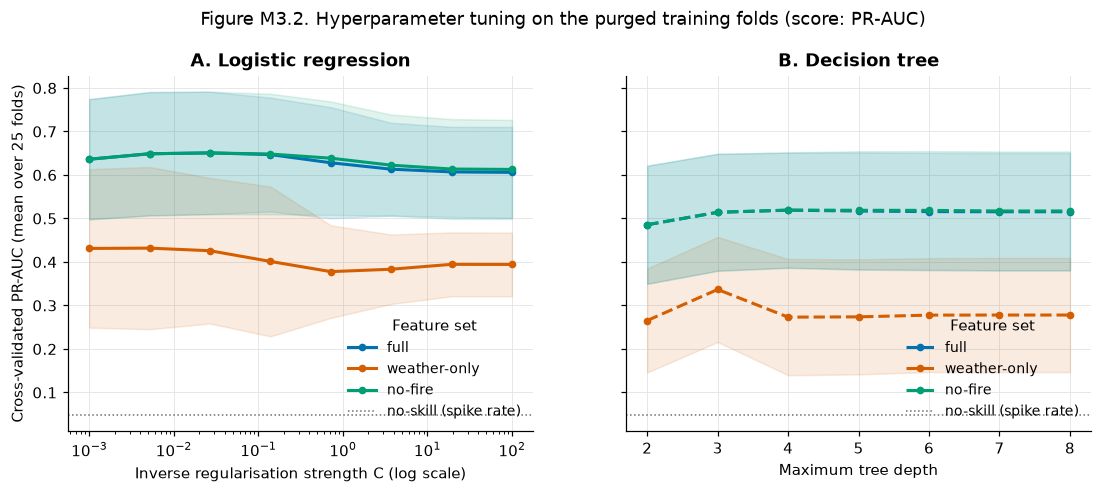

In [6]:
# Figure M3.2: tuning curves (best setting of the other hyperparameters at each value; band = ±1 SD over 25 folds)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, tab, x, xlabel, title in [
        (axes[0], tuning_lr, "C", "Inverse regularisation strength C (log scale)", "A. Logistic regression"),
        (axes[1], tuning_dt, "max_depth", "Maximum tree depth", "B. Decision tree")]:
    for s in SETS:
        best = tab[tab.feature_set == s].sort_values("cv_pr_auc_mean").groupby(x).tail(1).sort_values(x)
        ax.plot(best[x], best["cv_pr_auc_mean"], color=SET_COLOR[s], marker="o", ms=4,
                ls="-" if tab is tuning_lr else "--", label=SET_LABEL[s])
        ax.fill_between(best[x], best["cv_pr_auc_mean"] - best["cv_pr_auc_sd"],
                        best["cv_pr_auc_mean"] + best["cv_pr_auc_sd"], color=SET_COLOR[s], alpha=0.12)
    ax.axhline(y_tr.mean(), color=P.GREY, lw=1, ls=":", label="no-skill (spike rate)")
    ax.set_xlabel(xlabel); ax.set_title(title)
    ax.legend(title="Feature set", loc="lower right")
axes[0].set_xscale("log")
axes[0].set_ylabel("Cross-validated PR-AUC (mean over 25 folds)")
fig.suptitle("Figure M3.2. Hyperparameter tuning on the purged training folds (score: PR-AUC)", y=1.02)
P.save(fig, "fig_m3_2_tuning")
plt.show()

**Out-of-fold predictions and alert thresholds.** For every tuned model we refit the best setting on each of the 25
fit parts and predict its held-out part; each training row gets the mean of its 5 out-of-fold probabilities.
The alert threshold is the value that minimises `5·FN + 1·FP` on these out-of-fold predictions (decision D6).
**All thresholds are fixed here, before any validation metric is computed in M3.4.**

In [7]:
X_tr = {s: train[MD.FEATURE_SETS[s]] for s in SETS}
X_va = {s: val[MD.FEATURE_SETS[s]] for s in SETS}
fitted, oof, cv_folds, thresholds = {}, {}, {}, {}

assert_train_only(train)
fitted["majority"] = MD.make_majority().fit(X_tr["full"], y_tr)
oof["majority"], cv_folds["majority"] = MD.oof_predict(MD.make_majority(), X_tr["full"], y_tr, splits)
for m, gs in searches.items():
    fitted[m] = gs.best_estimator_
    oof[m], cv_folds[m] = MD.oof_predict(gs.best_estimator_, X_tr[m.split("_", 1)[1]], y_tr, splits)

for m in oof:
    thresholds[m], _ = MD.choose_threshold(y_tr, oof[m], COST_FN, COST_FP)
pers_score_tr, pers_yhat_tr = MD.persistence(train)
pers_score_va, pers_yhat_va = MD.persistence(val)

params = {
    "target": TARGET, "cost_fn_fp": [COST_FN, COST_FP], "threshold_rule": "min 5*FN + 1*FP on OOF train",
    "cv": {"type": "purged repeated StratifiedGroupKFold", "n_splits": 5, "seeds": list(range(5)),
           "group": "calendar week from WINDOW_START", "purge_days": H, "embargo_days": H + MD.MAX_AQ_LAG},
    "rows": {"train": len(train), "validation": len(val)},
    "feature_sets": MD.FEATURE_SETS,
    "models": {m: {"best_params": {k.replace("model__", ""): (None if v is None else
                                   float(v) if isinstance(v, (float, np.floating)) else v)
                                   for k, v in searches[m].best_params_.items()} if m in searches else {},
                   "cv_pr_auc": float(searches[m].best_score_) if m in searches else None,
                   "threshold": thresholds[m] if np.isfinite(thresholds[m]) else "never alert"}
               for m in MODELS if m != "persistence"},
}
params["models"]["persistence"] = {"rule": "alert when today's index >= city spike threshold"}
(C.CLEAN_DIR / "m3_params.json").write_text(json.dumps(params, indent=2))
print(pd.Series({LABEL[m]: thresholds[m] for m in thresholds}, name="alert threshold (OOF, 5:1)").round(4))

Majority class        inf
LR full            0.1280
DT full            0.1988
LR weather-only    0.1009
DT weather-only    0.1173
LR no-fire         0.1280
DT no-fire         0.1988
Name: alert threshold (OOF, 5:1), dtype: float64


**Leakage check: why not a random stratified split?** The brief asks for stratified sampling. We test what a
random stratified split would do on our data. The tuned LR full and DT full pipelines are scored four ways, on
**training rows only** (thresholds and hyperparameters are already frozen in `m3_params.json` above, so nothing
here can change a choice):
- **(a)** one random stratified 80/20 split of the training rows;
- **(b)** plain `StratifiedKFold(5, shuffle=True)`;
- **(c)** `StratifiedGroupKFold(5)` by calendar week, **without** purge or embargo;
- **(d)** our purged and embargoed 5 × 5 folds (M3.2).

The reference row is the chronological validation score (September to December 2023), the honest out-of-time test.
If (a) and (b) score well above (d) and validation, a random split overstates skill.

In [8]:
from sklearn.base import clone
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, train_test_split

assert_train_only(train)
idx_all = np.arange(len(train))
SCHEMES = {
    "(a) random stratified 80/20 split": [tuple(train_test_split(idx_all, test_size=0.2, stratify=y_tr, random_state=42))],
    "(b) StratifiedKFold(5, shuffle), no groups": list(StratifiedKFold(5, shuffle=True, random_state=0).split(idx_all, y_tr)),
    "(c) StratifiedGroupKFold(5) by week, no purge/embargo": list(
        StratifiedGroupKFold(5, shuffle=True, random_state=0).split(idx_all, y_tr, weeks)),
}
leak_rows = []
for m in ["lr_full", "dt_full"]:
    est, Xm = searches[m].best_estimator_, X_tr["full"]
    fold_sets = {k: [(t, clone(est).fit(Xm.iloc[f], y_tr[f]).predict_proba(Xm.iloc[t])[:, 1]) for f, t in sp]
                 for k, sp in SCHEMES.items()}
    fold_sets["(d) purged + embargoed 5 × 5 StratifiedGroupKFold (ours)"] = cv_folds[m]
    for k, folds in fold_sets.items():
        pr = [average_precision_score(y_tr[t], p) for t, p in folds]
        roc = [roc_auc_score(y_tr[t], p) for t, p in folds]
        leak_rows.append({"model": LABEL[m], "scheme": k, "n_folds": len(folds),
                          "pr_auc_mean": np.mean(pr), "pr_auc_sd": np.std(pr, ddof=1) if len(pr) > 1 else np.nan,
                          "roc_auc_mean": np.mean(roc), "roc_auc_sd": np.std(roc, ddof=1) if len(roc) > 1 else np.nan})
    p_val = fitted[m].predict_proba(val[MD.FEATURE_SETS["full"]])[:, 1]
    leak_rows.append({"model": LABEL[m], "scheme": "reference: chronological validation (Sep–Dec 2023)", "n_folds": 1,
                      "pr_auc_mean": average_precision_score(y_va, p_val), "pr_auc_sd": np.nan,
                      "roc_auc_mean": roc_auc_score(y_va, p_val), "roc_auc_sd": np.nan})
leakage = pd.DataFrame(leak_rows)
_ = save_table(leakage, "m3_leakage_check", index=False)
print(leakage.round(4).to_string(index=False))

  model                                                   scheme  n_folds  pr_auc_mean  pr_auc_sd  roc_auc_mean  roc_auc_sd
LR full                        (a) random stratified 80/20 split        1       0.7300        NaN        0.9755         NaN
LR full               (b) StratifiedKFold(5, shuffle), no groups        5       0.6769     0.0892        0.9735      0.0085
LR full    (c) StratifiedGroupKFold(5) by week, no purge/embargo        5       0.6508     0.1579        0.9724      0.0104
LR full (d) purged + embargoed 5 × 5 StratifiedGroupKFold (ours)       25       0.6508     0.1437        0.9723      0.0104
LR full       reference: chronological validation (Sep–Dec 2023)        1       0.6946        NaN        0.9665         NaN
DT full                        (a) random stratified 80/20 split        1       0.6524        NaN        0.9419         NaN
DT full               (b) StratifiedKFold(5, shuffle), no groups        5       0.6162     0.0927        0.9669      0.0168
DT full 

**What we found (leakage check): a random stratified split overstates skill.**
- **LR full.** PR-AUC 0.730 on one random stratified 80/20 split and 0.677 ± 0.089 with plain StratifiedKFold, against 0.651 ± 0.158 with week groups and 0.651 ± 0.144 with our purged and embargoed folds. Random splitting inflates PR-AUC by 0.03 to 0.08.
- **DT full.** 0.652 (random 80/20) and 0.616 (StratifiedKFold) against 0.539 (week groups, no purge) and 0.519 (ours): an inflation of 0.10 to 0.13. Purge and embargo remove a further 0.020 for the tree and nothing for the sparse LR, which uses only today's margin and temperature.
- **ROC-AUC hides it.** ROC-AUC moves by at most 0.03 across the schemes. The inflation shows in PR-AUC, the metric that focuses on the rare spikes.
- **The validation season was easier.** The chronological validation scores (LR 0.695, DT 0.590) sit above our CV, because the December 2023 episodes were long and persistent: persistence itself scores 0.669 on validation against 0.636 in CV. The inflation is therefore measured against grouped CV on the same training rows, not against validation.
- **Design consequence.** Grouping by week does most of the work. Stratification is kept, but inside the grouped folds, where every fold still gets its share of spikes (M3.2).

**What we found (M3.3).**
- **Logistic regression is the stronger learner.** LR full reaches a CV PR-AUC of **0.651** (C = 0.027, L1, no class weights), and LR no-fire picks the same setting (0.651). The L1 penalty keeps only **2 of the 42 columns**: today's margin over the city threshold and the mean temperature. The tuning curve is flat between C = 0.005 and 0.14 (0.643 to 0.651) and falls as the regularisation weakens (0.605 at C = 100), so the optimum lies inside the grid. L1 beats L2 at every C up to 0.14.
- **The tree.** DT full reaches 0.519 (depth 4, leaf 50, no class weights), and DT no-fire the same. Depth 4 is the peak; deeper trees stay flat (0.516 to 0.517).
- **AQ history is the lever.** Without it, the weather-only LR falls to 0.432 and prefers strong regularisation (C = 0.005, L2), the sign of a weak signal; the weather-only tree reaches 0.337.
- **Fire adds nothing.** Full and no-fire pick identical settings and differ by less than 0.001 in CV PR-AUC.
- **Against the benchmark.** Persistence scores a CV PR-AUC of 0.636, just below LR full (0.651) and well above the trees.
- **Thresholds.** No class weights were chosen anywhere, so the 5:1 thresholds are plain probabilities: alert when the spike probability is at least 12.8% (LR full) or 19.9% (DT full).

---
## M3.4 Metrics

**Cross-validated (25 folds):** mean ± SD of each metric over the held-out folds, each fold scored with the model's
out-of-fold threshold. Because that threshold was chosen on the same pooled out-of-fold predictions, the CV
threshold metrics are slightly optimistic; the threshold-free AUCs are not affected.

**Validation (2023-09-04 to 2023-12-31, never used for any fit or choice; only the leakage-check reference row above looked at it, after every threshold was frozen):** point estimates with 95% CIs from a
**block bootstrap** that resamples whole calendar weeks (all cities of a week together, 1,000 resamples), so the
CIs respect the day-to-day and city-to-city dependence.

In [9]:
METRICS = ["accuracy", "precision", "recall", "specificity", "f1", "roc_auc", "pr_auc", "brier", "cost_per_1000"]

cv_rows = {"persistence": EV.cv_metrics(y_tr, [(t, pers_score_tr[t]) for _, t in splits], yhat=pers_yhat_tr)}
for m in oof:
    cv_rows[m] = EV.cv_metrics(y_tr, cv_folds[m], threshold=thresholds[m])
metrics_cv = pd.DataFrame(cv_rows).T.loc[MODELS]
metrics_cv.index = [LABEL[m] for m in MODELS]
metrics_cv.index.name = "model"
keep = [f"{k}_{s}" for k in METRICS for s in ("mean", "sd")]
_ = save_table(metrics_cv[keep], "m3_metrics_cv")
print("Cross-validated metrics (mean over 25 folds; SD in brackets)")
print(pd.DataFrame({k: metrics_cv[f"{k}_mean"].round(3).astype(str) + " (" + metrics_cv[f"{k}_sd"].round(3).astype(str) + ")"
                    for k in METRICS}).to_string())

# Validation scores and predictions for every model
score_va, yhat_va = {"persistence": pers_score_va}, {"persistence": pers_yhat_va}
for m in oof:
    score_va[m] = fitted[m].predict_proba(X_va["full" if m == "majority" else m.split("_", 1)[1]])[:, 1]
    yhat_va[m] = (score_va[m] >= thresholds[m]).astype(int)
vframe = val[["city", "date", "persist_spike", TARGET, "target_index_h1"]].copy()
for m in MODELS:
    vframe[f"s_{m}"], vframe[f"p_{m}"] = score_va[m], yhat_va[m]

# Hand count check: persistence on validation equals a direct cross-tab of persist_spike vs the target
hand = pd.crosstab(val["persist_spike"], val[TARGET])
pm = EV.binary_metrics(y_va, pers_score_va, yhat=pers_yhat_va)
assert (pm["tp"], pm["fp"], pm["fn"], pm["tn"]) == (hand.loc[1, 1], hand.loc[1, 0], hand.loc[0, 1], hand.loc[0, 0])


def all_model_metrics(d):
    out = {}
    for m in MODELS:
        r = EV.binary_metrics(d[TARGET], d[f"s_{m}"], yhat=d[f"p_{m}"])
        out.update({f"{m}|{k}": r[k] for k in METRICS})
    return out


boot = EV.block_bootstrap(vframe, all_model_metrics, n=N_BOOT, seed=42)
boot.index = pd.MultiIndex.from_tuples([tuple(i.split("|")) for i in boot.index], names=["model", "metric"])
counts = pd.DataFrame({m: EV.binary_metrics(y_va, score_va[m], yhat=yhat_va[m]) for m in MODELS}).T
metrics_val = boot.reset_index()
metrics_val["model"] = metrics_val["model"].map(LABEL)
_ = save_table(metrics_val, "m3_metrics_validation", index=False)
counts.index = [LABEL[m] for m in MODELS]
_ = save_table(counts[["tp", "fp", "tn", "fn", "n"]].astype(int), "m3_validation_counts")

fmt = boot.apply(lambda r: f"{r.estimate:.3f} [{r.ci_low:.3f}, {r.ci_high:.3f}]", axis=1).unstack("metric")
fmt = fmt.loc[MODELS, METRICS]; fmt.index = [LABEL[m] for m in MODELS]
print(f"\nValidation metrics, 95% block-bootstrap CI ({boot['n_weeks'].iloc[0]} weeks resampled)")
print(fmt.to_string())
print("\nValidation confusion counts"); print(counts[["tp", "fp", "tn", "fn"]].astype(int).to_string())

Cross-validated metrics (mean over 25 folds; SD in brackets)
                      accuracy      precision         recall    specificity             f1        roc_auc         pr_auc          brier     cost_per_1000
model                                                                                                                                                    
Majority class   0.952 (0.013)            NaN      0.0 (0.0)      1.0 (0.0)      0.0 (0.0)            NaN            NaN  0.048 (0.013)  240.563 (67.286)
Persistence      0.961 (0.005)  0.579 (0.134)  0.579 (0.123)  0.979 (0.006)   0.575 (0.12)  0.969 (0.012)  0.636 (0.141)            NaN  113.973 (12.686)
LR full           0.927 (0.02)  0.396 (0.099)  0.924 (0.062)  0.927 (0.022)  0.546 (0.103)   0.972 (0.01)  0.651 (0.144)  0.028 (0.003)   86.678 (18.394)
LR weather-only   0.903 (0.07)  0.402 (0.254)  0.669 (0.158)  0.916 (0.078)  0.447 (0.194)  0.898 (0.046)   0.432 (0.19)   0.041 (0.01)  162.315 (50.327)
LR no-fire     


Validation metrics, 95% block-bootstrap CI (18 weeks resampled)
metric                       accuracy             precision                recall           specificity                    f1               roc_auc                pr_auc                 brier               cost_per_1000
Majority class   0.931 [0.869, 0.983]        nan [nan, nan]  0.000 [0.000, 0.000]  1.000 [1.000, 1.000]  0.000 [0.000, 0.000]        nan [nan, nan]        nan [nan, nan]  0.069 [0.017, 0.131]   342.835 [86.558, 656.699]
Persistence      0.955 [0.921, 0.985]  0.688 [0.474, 0.757]  0.618 [0.370, 0.703]  0.979 [0.960, 0.994]  0.651 [0.422, 0.712]  0.963 [0.937, 0.979]  0.669 [0.344, 0.765]        nan [nan, nan]   150.231 [48.418, 263.968]
LR full          0.920 [0.873, 0.965]  0.456 [0.222, 0.582]  0.865 [0.667, 0.926]  0.924 [0.874, 0.969]  0.597 [0.333, 0.708]  0.966 [0.940, 0.983]  0.695 [0.323, 0.790]  0.037 [0.013, 0.065]   117.103 [51.824, 189.270]
LR weather-only  0.807 [0.669, 0.940]  0.228 [0.038, 0.

**What we found (M3.4).**
- **Accuracy is the wrong yardstick.** The majority class scores 93.1% accuracy on validation, higher than LR full (92.0%), but it catches no spike and has the highest real cost (342.8 per 1,000 city-days).
- **LR full ranks spikes at least as well as persistence.** Its validation PR-AUC is **0.695** [0.323, 0.790] and its ROC-AUC 0.966, against **0.669** [0.344, 0.765] and 0.963 for persistence. DT full scores 0.590 [0.237, 0.716] and 0.953. The CIs overlap almost completely (the paired test is in M3.5).
- **Both models win at the alert decision.** With the 5:1 thresholds, LR full catches **86.5%** of spikes (77 of 89) against 61.8% (55 of 89) for persistence, at lower precision (45.6% vs 68.8%). Its expected cost is **117.1** per 1,000 city-days against 150.2 for persistence. DT full catches 82.0% (73) at a precision of 52.1% and has the lowest cost, 113.3.
- **LR full and LR no-fire are identical on validation**: the L1 penalty sets every fire coefficient to zero in both.
- **CV tells the same story.** PR-AUC: persistence 0.636 ± 0.141, LR full 0.651 ± 0.144, DT full 0.519 ± 0.135. Cost: 114.0, 86.7 and 92.4.
- **Wide CIs.** With only 18 validation weeks, and 77 of the 89 spikes in December, the CIs are wide.

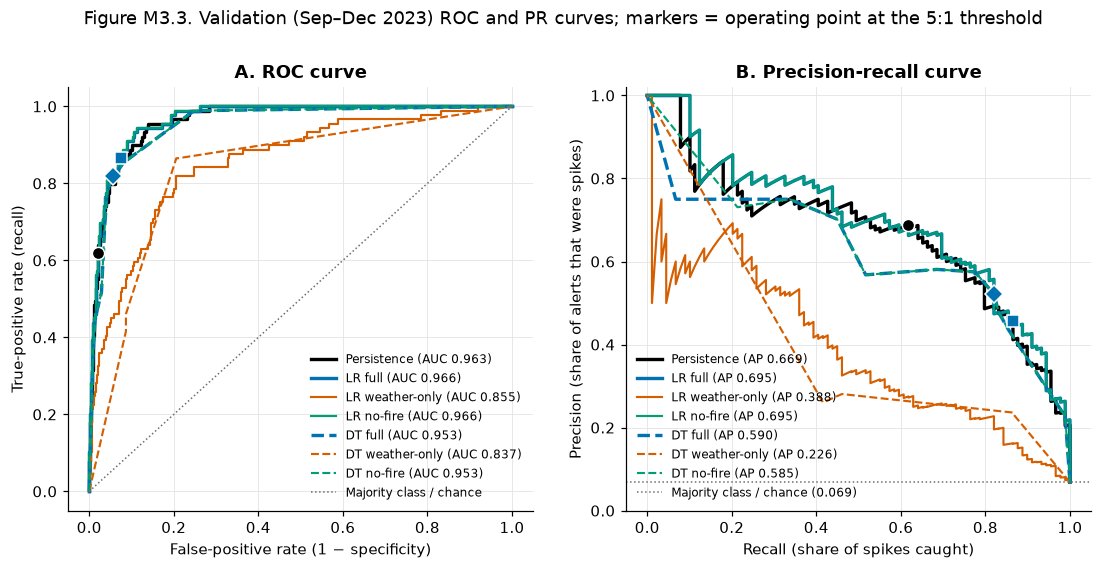

In [10]:
# Figure M3.3: ROC and precision-recall curves on validation
from sklearn.metrics import precision_recall_curve, roc_curve

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for m in MODELS[1:]:
    fpr, tpr, _ = roc_curve(y_va, score_va[m])
    prec, rec, _ = precision_recall_curve(y_va, score_va[m])
    kw = dict(color=COLOR[m], ls=STYLE[m], lw=2.2 if m in ("persistence", "lr_full", "dt_full") else 1.4)
    axes[0].plot(fpr, tpr, label=f"{LABEL[m]} (AUC {boot.loc[(m, 'roc_auc'), 'estimate']:.3f})", **kw)
    axes[1].plot(rec, prec, label=f"{LABEL[m]} (AP {boot.loc[(m, 'pr_auc'), 'estimate']:.3f})", **kw)
for m, mk in [("persistence", "o"), ("lr_full", "s"), ("dt_full", "D")]:
    c = counts.loc[LABEL[m]]
    axes[0].plot(c.fp / (c.fp + c.tn), c.tp / (c.tp + c.fn), mk, color=COLOR[m], ms=8, mec="white")
    axes[1].plot(c.tp / (c.tp + c.fn), c.tp / max(c.tp + c.fp, 1), mk, color=COLOR[m], ms=8, mec="white")
axes[0].plot([0, 1], [0, 1], color=P.GREY, ls=":", lw=1, label="Majority class / chance")
axes[1].axhline(y_va.mean(), color=P.GREY, ls=":", lw=1, label=f"Majority class / chance ({y_va.mean():.3f})")
axes[0].set(xlabel="False-positive rate (1 − specificity)", ylabel="True-positive rate (recall)",
            title="A. ROC curve")
axes[1].set(xlabel="Recall (share of spikes caught)", ylabel="Precision (share of alerts that were spikes)",
            title="B. Precision-recall curve", ylim=(0, 1.02))
axes[0].legend(loc="lower right", fontsize=8)
axes[1].legend(loc="lower left", fontsize=8)
fig.suptitle("Figure M3.3. Validation (Sep–Dec 2023) ROC and PR curves; markers = operating point at the 5:1 threshold",
             y=1.02)
P.save(fig, "fig_m3_3_roc_pr")
plt.show()

---
## M3.5 Fire ablation: do upwind fires add skill?

The core project question. We compare each model with fire features (**full**) against the same model fitted
without the four fire columns (**no-fire**), on the same rows:
- **Validation:** paired block-bootstrap difference (full − no-fire) in PR-AUC and ROC-AUC; both models are scored
  on the same resampled weeks, so the CI is for the difference itself.
- **CV:** the paired difference fold by fold over the 25 training folds.

The same comparison against **persistence** shows whether any model beats "tomorrow = today".

In [11]:
from sklearn.metrics import average_precision_score, roc_auc_score

PAIRS = [("lr_full", "lr_no_fire"), ("dt_full", "dt_no_fire"), ("lr_full", "lr_weather_only"),
         ("dt_full", "dt_weather_only"), ("lr_no_fire", "lr_weather_only"),
         ("lr_full", "persistence"), ("dt_full", "persistence"), ("lr_no_fire", "persistence")]


def auc_pair(d, a, b):
    if d[TARGET].nunique() < 2:
        return {"d_pr_auc": np.nan, "d_roc_auc": np.nan}
    return {"d_pr_auc": average_precision_score(d[TARGET], d[f"s_{a}"]) - average_precision_score(d[TARGET], d[f"s_{b}"]),
            "d_roc_auc": roc_auc_score(d[TARGET], d[f"s_{a}"]) - roc_auc_score(d[TARGET], d[f"s_{b}"])}


rows = []
for a, b in PAIRS:
    bb = EV.block_bootstrap(vframe, lambda d: auc_pair(d, a, b), n=N_BOOT, seed=42)
    cv_d = []
    for (_, t), (_, pa), (_, pb) in zip(splits, cv_folds.get(a, [(None, pers_score_tr[t]) for _, t in splits]),
                                        cv_folds.get(b, [(None, pers_score_tr[t]) for _, t in splits])):
        cv_d.append((average_precision_score(y_tr[t], pa) - average_precision_score(y_tr[t], pb),
                     roc_auc_score(y_tr[t], pa) - roc_auc_score(y_tr[t], pb)))
    cv_d = np.array(cv_d)
    for k, metric in enumerate(["pr_auc", "roc_auc"]):
        r = bb.loc[f"d_{metric}"]
        rows.append({"comparison": f"{LABEL[a]} − {LABEL[b]}", "metric": metric,
                     "validation_diff": r.estimate, "ci_low": r.ci_low, "ci_high": r.ci_high,
                     "ci_excludes_0": bool(r.ci_low > 0 or r.ci_high < 0),
                     "cv_diff_mean": cv_d[:, k].mean(), "cv_diff_sd": cv_d[:, k].std(ddof=1),
                     "cv_folds_a_better": int((cv_d[:, k] > 0).sum())})
ablation = pd.DataFrame(rows)
_ = save_table(ablation, "m3_fire_ablation", index=False)
print(ablation.round(4).to_string(index=False))

                  comparison  metric  validation_diff  ci_low  ci_high  ci_excludes_0  cv_diff_mean  cv_diff_sd  cv_folds_a_better
        LR full − LR no-fire  pr_auc           0.0000  0.0000   0.0000          False        0.0000      0.0000                  2
        LR full − LR no-fire roc_auc           0.0000  0.0000   0.0000          False        0.0000      0.0000                  2
        DT full − DT no-fire  pr_auc           0.0041 -0.0121   0.0169          False       -0.0003      0.0020                  6
        DT full − DT no-fire roc_auc           0.0001 -0.0003   0.0004          False        0.0001      0.0011                  7
   LR full − LR weather-only  pr_auc           0.3067  0.1883   0.3788           True        0.2189      0.1075                 25
   LR full − LR weather-only roc_auc           0.1117  0.0516   0.3170           True        0.0739      0.0400                 25
   DT full − DT weather-only  pr_auc           0.3639  0.1746   0.4728           Tr

**What we found (M3.5): upwind fires add no next-day skill once today's smog is known.**
- **LR.** The tuned L1 penalty sets all four fire coefficients to zero in the refitted model. LR full and LR no-fire therefore give identical validation predictions (ΔPR-AUC = 0). Across the 25 CV refits a fire term survives in a few folds, and the full model is better in only 2 of 25 folds (mean Δ 0.0000).
- **DT.** The tree shows the same null: ΔPR-AUC +0.004 [−0.012, +0.017], ΔROC-AUC +0.0001; better in 6 of 25 folds (mean −0.0003). The only fire split in the full tree (fire lag 3) carries 0.2% of its Gini importance.
- **AQ history is what matters.** LR full minus LR weather-only is **ΔPR-AUC +0.307** [+0.188, +0.379], better in 25 of 25 folds (DT: +0.364).
- **LR edges past persistence, but only just.** LR full minus persistence is ΔPR-AUC **+0.026** [−0.020, +0.052] (better in 19 of 25 folds, mean +0.015) and ΔROC-AUC +0.0036 [+0.0009, +0.0059] (better in 21 of 25 folds). The ranking gain is small but consistent; the PR-AUC CI includes 0. DT full loses on ranking (ΔPR-AUC −0.079 [−0.114, −0.036], better in 0 of 25 folds).
- **Interpretation.** This does not show that fires do not cause smog. Milestone 2 found the cone fires correlate with the next-day index (ρ ≈ 0.24). Whatever smoke the fires add is already in today's index, which is the strongest single input. At a one-day horizon, the extra information in today's fire count is too small to detect.

---
## M3.6 Asymmetric error cost

The two errors do not cost the same. A **false negative** (a spike day with no advisory) leaves children, the
elderly, outdoor workers and asthma patients exposed without warning, at PM2.5 levels already several times the
WHO guideline; health effects of a single high-exposure day include hospital admissions for asthma and COPD.
A **false positive** (an advisory on a normal day) costs a needless school closure or kiln and traffic restriction,
lost wages, and, if repeated, **alert fatigue** that makes people ignore the next real warning.

| | Who bears it | Consequence | Reversible? |
|---|---|---|---|
| **FN: missed spike** | sensitive groups, outdoor workers, hospitals | unprotected exposure, respiratory and cardiac admissions, lost school days through illness | no (exposure has happened) |
| **FP: false alarm** | schools, brick kilns, transport, daily-wage workers | closures, lost income, reduced trust in future alerts | mostly yes (one day of disruption) |

We weight **FN:FP = 5:1** as the headline (decision D6). This ratio is a **stated policy assumption, not an estimate**:
we found no verified study that prices one missed smog day against one unnecessary advisory day in Punjab. The scale
of the health side is documented. In India in 2019, air pollution was linked to 1.67 million deaths (17.8% of all
deaths) and to lost output of US\$36.8 billion, 1.36% of GDP (Pandey et al. 2021, *Lancet Planetary Health* 5:
e25–e38). Because the ratio itself is uncertain, the robust result is the **break-even ratio**: the smallest FN:FP
ratio at which a model alert is cheaper than persistence or than never alerting. We show the conclusions for every
ratio from 1 to 20.
For each ratio the threshold is re-optimised on the out-of-fold training predictions; validation only reports the
cost. Two reference policies frame the curve: **never alert** (cost = ratio × spikes) and **always alert**
(cost = non-spike days).

In [12]:
RATIOS = range(1, 21)
curves = []
for m in ["persistence", "lr_full", "lr_no_fire", "lr_weather_only", "dt_full", "dt_no_fire", "dt_weather_only"]:
    if m == "persistence":
        c = EV.cost_curve(y_tr, pers_score_tr, y_va, pers_score_va, RATIOS, yhat_val=pers_yhat_va)
    else:
        c = EV.cost_curve(y_tr, oof[m], y_va, score_va[m], RATIOS)
    curves.append(c.assign(model=LABEL[m]))
curve = pd.concat(curves)
_ = save_table(curve, "m3_cost_curve", index=False)

wide = curve.pivot(index="ratio", columns="model", values="cost_per_1000")
never = curve.groupby("ratio")["never_alert"].first()
always = curve.groupby("ratio")["always_alert"].first()
cost_rows = []
for m in ["majority"] + [LABEL[k] for k in ["persistence", "lr_full", "lr_no_fire", "lr_weather_only",
                                            "dt_full", "dt_no_fire", "dt_weather_only"]]:
    if m == "majority":
        c5 = never.loc[COST_FN]; fn_, fp_ = int(y_va.sum()), 0
        beats_never, beats_pers = [], []
    else:
        r5 = curve[(curve.model == m) & (curve.ratio == COST_FN)].iloc[0]
        c5, fn_, fp_ = r5.cost_per_1000, int(r5.fn), int(r5.fp)
        beats_never = [r for r in RATIOS if wide.loc[r, m] < never.loc[r]]
        beats_pers = [r for r in RATIOS if wide.loc[r, m] < wide.loc[r, "Persistence"]]
    cost_rows.append({"model": "Majority class (= never alert)" if m == "majority" else m,
                      "cost_per_1000_at_5to1": c5, "fn": fn_, "fp": fp_,
                      "saving_vs_never_alert_pct": 100 * (1 - c5 / never.loc[COST_FN]),
                      "break_even_ratio_vs_never_alert": min(beats_never) if beats_never else np.nan,
                      "ratios_beating_persistence": len(beats_pers)})
cost = pd.DataFrame(cost_rows)
cost.loc[len(cost)] = {"model": "Always alert", "cost_per_1000_at_5to1": always.loc[COST_FN],
                       "fn": 0, "fp": int((y_va == 0).sum()),
                       "saving_vs_never_alert_pct": 100 * (1 - always.loc[COST_FN] / never.loc[COST_FN])}
_ = save_table(cost, "m3_cost", index=False)
print(cost.round(2).to_string(index=False))

                         model  cost_per_1000_at_5to1  fn   fp  saving_vs_never_alert_pct  break_even_ratio_vs_never_alert  ratios_beating_persistence
Majority class (= never alert)                 342.84  89    0                       0.00                              NaN                         0.0
                   Persistence                 150.23  34   25                      56.18                              1.0                         0.0
                       LR full                 117.10  12   92                      65.84                              1.0                        19.0
                    LR no-fire                 117.10  12   92                      65.84                              1.0                        19.0
               LR weather-only                 258.09  21  230                      24.72                              2.0                         7.0
                       DT full                 113.25  16   67                      66.97     

**What we found (M3.6).**
- **At 5:1.** Never alerting costs **342.8** per 1,000 city-days, and always alerting 931.4. Persistence cuts that to 150.2 (34 missed spikes, 25 false alarms). LR full cuts it to **117.1** (12 missed, 92 false alarms), a 65.8% saving over never alerting. DT full is the cheapest at **113.3** (16 missed, 67 false alarms; 67.0% saving).
- **The cost curve and the break-even ratio.** Persistence is cheapest only at 1:1 (45.5 against 48.5 for LR full). **From 2:1 upwards both LR full and DT full are cheaper than persistence**, and the gap widens with the ratio: at 20:1, LR full costs 255.8, DT full 275.8 and persistence 543.1. LR and DT stay within 4 cost units of each other up to 7:1; above that LR is cheaper.
- **Policy reading.** A health department only has to judge a missed smog day at least twice as costly as an unnecessary advisory for a model alert to beat "tomorrow = today". Given the health burden above, that is a low bar. The price is more false alarms: 7.6% of non-spike days for LR full (92 of 1,209) and 5.5% for DT full (67), against 2.1% for persistence.

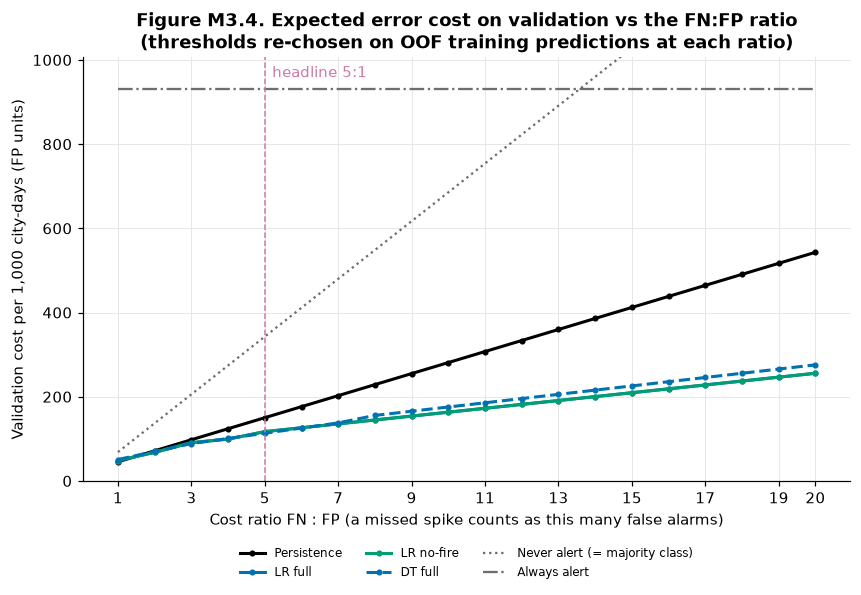

In [13]:
# Figure M3.4: validation cost curve
fig, ax = plt.subplots(figsize=(9, 5))
for m in ["persistence", "lr_full", "lr_no_fire", "dt_full"]:
    ax.plot(wide.index, wide[LABEL[m]], color=COLOR[m], ls=STYLE[m], marker="o", ms=3, label=LABEL[m])
ax.plot(never.index, never, color=P.GREY, ls=":", lw=1.5, label="Never alert (= majority class)")
ax.plot(always.index, always, color=P.GREY, ls="-.", lw=1.5, label="Always alert")
ax.axvline(COST_FN, color=P.CAT_COLORS[4], lw=1, ls="--")
ax.set_xlabel("Cost ratio FN : FP (a missed spike counts as this many false alarms)")
ax.set_ylabel("Validation cost per 1,000 city-days (FP units)")
ax.set_xticks(list(RATIOS)[::2] + [20])
ax.set_ylim(0, always.max() * 1.08)
ax.text(COST_FN + 0.2, always.max() * 1.04, "headline 5:1", color=P.CAT_COLORS[4], va="center")
ax.set_title("Figure M3.4. Expected error cost on validation vs the FN:FP ratio\n(thresholds re-chosen on OOF training predictions at each ratio)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3, fontsize=8)
P.save(fig, "fig_m3_4_cost_curve")
plt.show()

---
## M3.7 Confusion matrices and edge cases

Confusion matrices on validation at the 5:1 threshold for persistence, LR-full and DT-full. Errors are then split by
**onset** days (tomorrow is a spike but today is not, `persist_spike == 0`) and **continuation** days (today is
already a spike). Persistence cannot catch an onset by construction; onsets are where a forecast adds value.

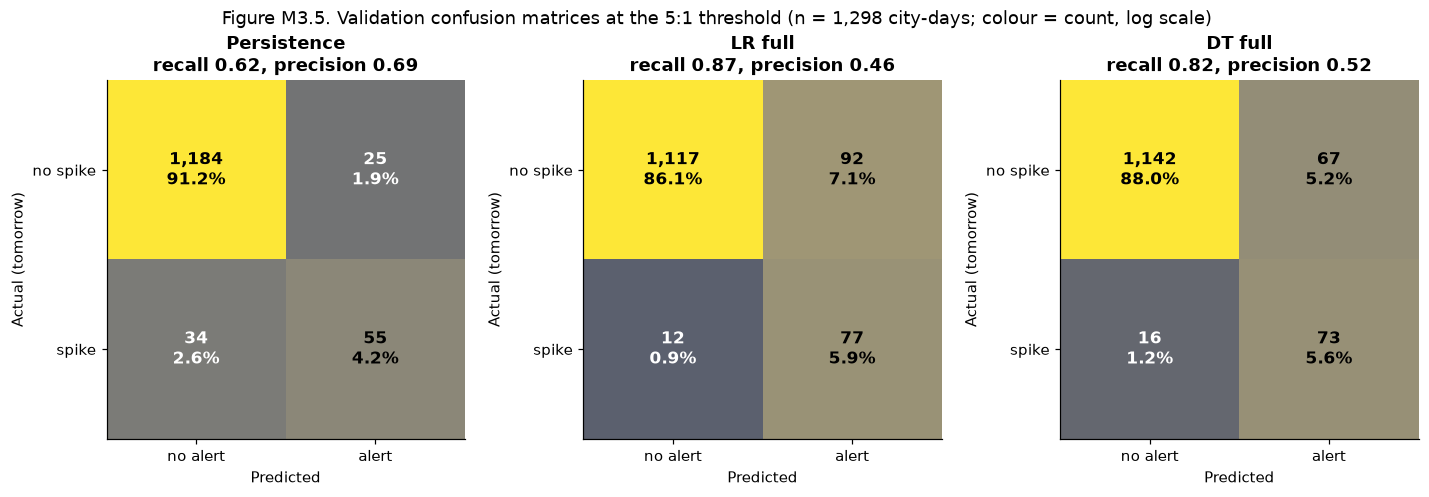

Spikes caught and missed on onset vs continuation days (validation):
outcome                   FN  FP  TP  recall
model       day_type                        
DT full     continuation   0  25  55   1.000
            onset         16  42  18   0.529
LR full     continuation   0  25  55   1.000
            onset         12  67  22   0.647
Persistence continuation   0  25  55   1.000
            onset         34   0   0   0.000

Errors by month (all cities):
         spikes                          fn                          fp                    
model   DT full LR full Persistence DT full LR full Persistence DT full LR full Persistence
month                                                                                      
2023-09       0       0           0       0       0           0       0       0           0
2023-10       0       0           0       0       0           0       2       2           0
2023-11      12      12          12       4       4           6      16      25 

In [14]:
CM_MODELS = ["persistence", "lr_full", "dt_full"]
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), layout="constrained")
conf_rows = []
for ax, m in zip(axes, CM_MODELS):
    c = counts.loc[LABEL[m]]
    cm = np.array([[c.tn, c.fp], [c.fn, c.tp]], dtype=int)
    ax.imshow(cm, cmap=P.SEQ_CMAP, norm=plt.matplotlib.colors.LogNorm(vmin=1, vmax=cm.max()))
    for i in range(2):
        for j in range(2):
            v = cm[i, j]
            ax.text(j, i, f"{v:,}\n{100 * v / cm.sum():.1f}%", ha="center", va="center",
                    color="white" if v < np.sqrt(cm.max()) else "black", fontsize=11, fontweight="bold")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["no alert", "alert"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["no spike", "spike"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual (tomorrow)")
    ax.grid(False)
    ax.set_title(f"{LABEL[m]}\nrecall {c.tp / (c.tp + c.fn):.2f}, precision {c.tp / max(c.tp + c.fp, 1):.2f}")
    conf_rows.append({"model": LABEL[m], "tn": c.tn, "fp": c.fp, "fn": c.fn, "tp": c.tp})
fig.suptitle(f"Figure M3.5. Validation confusion matrices at the 5:1 threshold (n = {len(val):,} city-days; "
             "colour = count, log scale)", y=1.04)
P.save(fig, "fig_m3_5_confusion")
plt.show()
_ = save_table(pd.DataFrame(conf_rows).astype({k: int for k in ["tn", "fp", "fn", "tp"]}), "m3_confusion", index=False)

onset_rows, cm_rows, breakdown = [], [], {}
for m in CM_MODELS:
    b = EV.error_breakdown(val, y_va, yhat_va[m], score_va[m])
    breakdown[m] = b
    ot = b["onset"].reindex(index=["TP", "FN", "FP"], columns=["onset", "continuation"], fill_value=0)
    for err in ot.index:
        for dt in ot.columns:
            onset_rows.append({"model": LABEL[m], "outcome": err, "day_type": dt, "count": int(ot.loc[err, dt])})
    r = b["rows"]
    g = r.assign(fn=(r.error == "FN").astype(int), fp=(r.error == "FP").astype(int),
                 spikes=r.y).groupby(["city", "month"])[["spikes", "fn", "fp"]].sum().reset_index()
    cm_rows.append(g.assign(model=LABEL[m]))
errors_onset = pd.DataFrame(onset_rows)
errors_cm = pd.concat(cm_rows)[["model", "city", "month", "spikes", "fn", "fp"]]
_ = save_table(errors_onset, "m3_errors_onset", index=False)
_ = save_table(errors_cm, "m3_errors_city_month", index=False)

piv = errors_onset.pivot_table(index=["model", "day_type"], columns="outcome", values="count").fillna(0).astype(int)
piv["recall"] = piv["TP"] / (piv["TP"] + piv["FN"])
print("Spikes caught and missed on onset vs continuation days (validation):")
print(piv.round(3).to_string())
print("\nErrors by month (all cities):")
print(errors_cm.groupby(["model", "month"])[["spikes", "fn", "fp"]].sum().unstack("model").to_string())
print("\nErrors by city (all months):")
print(errors_cm.groupby(["model", "city"])[["fn", "fp"]].sum().unstack("model").to_string())

**What we found (M3.7).**
- **Onsets are where a model adds value.** Persistence misses every **onset** spike by construction (0 of 34). LR full catches **22 of 34 onsets (64.7%)** and all 55 continuation days. DT full catches 18 of 34 onsets (52.9%) and all continuations.
- **When the errors happen.** Every validation spike falls in November (12) or December (77). LR misses 4 in November and 8 in December, against 6 and 28 for persistence. Its 92 false alarms fall in December (65), November (25) and October (2). Of these, 67 are on days that were not spikes yet (onset type) and 25 on the last spike day of an episode (today a spike, tomorrow not).
- **Where the errors happen.** LR's 12 missed spikes are spread out (Faisalabad, Ferozepur and Multan 3 each; no other city above 1). False alarms concentrate in Rahim Yar Khan (16), Multan (14), Faisalabad (13), Ferozepur (12) and Jalandhar (11). Lahore had 1 validation spike and the twin Islamabad/Rawalpindi series none.

In [15]:
top = breakdown["lr_full"]
top_fn = top["top_fn"].assign(kind="FN: missed spike (highest next-day index)")
top_fp = top["top_fp"].assign(kind="FP: false alarm (highest score)")
top_errors = pd.concat([top_fn, top_fp]).rename(columns={"score": "lr_full_probability"})
top_errors["date"] = top_errors["date"].dt.date
_ = save_table(top_errors, "m3_top_errors", index=False)
print("LR full: the 10 worst missed spikes and the 10 most confident false alarms")
print(top_errors.round(3).to_string(index=False))

# Context for the edge cases: weather on the missed-spike days vs caught-spike days
r = top["rows"].join(val[["stagnant", "rh_mean_pct", "rain_day", "fire_cnt_up45_r300_all", "persist_index",
                          "spike_threshold"]])
ctx = r[r.y == 1].groupby("error")[["stagnant", "rh_mean_pct", "rain_day", "fire_cnt_up45_r300_all"]].mean()
ctx["today_margin"] = r[r.y == 1].assign(m=lambda d: d.persist_index - d.spike_threshold).groupby("error")["m"].mean()
ctx["n"] = r[r.y == 1].groupby("error").size()
print("\nSpike days, LR full: conditions on the feature day for caught (TP) vs missed (FN) spikes")
print(ctx.round(3).to_string())
_ = save_table(ctx, "m3_fn_context")

LR full: the 10 worst missed spikes and the 10 most confident false alarms
          city       date     day_type  target_index_h1  lr_full_probability                                      kind
      Amritsar 2023-12-25        onset            1.846                0.091 FN: missed spike (highest next-day index)
    Faisalabad 2023-12-28        onset            1.720                0.044 FN: missed spike (highest next-day index)
    Faisalabad 2023-12-08        onset            1.608                0.119 FN: missed spike (highest next-day index)
    Faisalabad 2023-12-25        onset            1.596                0.040 FN: missed spike (highest next-day index)
     Ferozepur 2023-12-13        onset            1.467                0.094 FN: missed spike (highest next-day index)
        Multan 2023-11-18        onset            1.435                0.125 FN: missed spike (highest next-day index)
       Sialkot 2023-12-20        onset            1.351                0.106 FN: missed spik

**Preliminary disparity check: error rates by country and city.** Does the alert serve Pakistani and Indian
cities equally? For persistence and LR full on validation we compute, per country, the spikes, alerts, recall
(share of spikes warned), false-positive rate (share of clean days with a needless alert) and precision, with 95%
week-block bootstrap CIs, plus the PK − IN gap on the same resampled weeks. Per city the same rates are point
estimates (5 to 22 spikes per city, too few for CIs). The full fairness audit is a Milestone 4 item.

In [16]:
gframe = vframe.join(val[["country"]])
COUNTRY = {"PK": "Pakistan (7 cities)", "IN": "India (4 cities)"}
grp_rows = []
for m in ["persistence", "lr_full"]:
    rate = lambda d: EV.group_error_rates(d[TARGET], d[f"p_{m}"])
    for ctry in ["PK", "IN"]:
        bb = EV.block_bootstrap(gframe[gframe.country == ctry], rate, n=N_BOOT, seed=42)
        grp_rows += [{"model": LABEL[m], "level": "country", "group": COUNTRY[ctry], "metric": k,
                      "estimate": r.estimate, "ci_low": r.ci_low, "ci_high": r.ci_high} for k, r in bb.iterrows()]

    def gap(d):
        a, b = rate(d[d.country == "PK"]), rate(d[d.country == "IN"])
        return {k: a[k] - b[k] for k in ["recall", "fpr", "precision"]}

    bb = EV.block_bootstrap(gframe, gap, n=N_BOOT, seed=42)
    grp_rows += [{"model": LABEL[m], "level": "country gap", "group": "PK − IN", "metric": k,
                  "estimate": r.estimate, "ci_low": r.ci_low, "ci_high": r.ci_high} for k, r in bb.iterrows()]
    for city, sub in gframe.groupby("city"):
        grp_rows += [{"model": LABEL[m], "level": "city", "group": city, "metric": k,
                      "estimate": v, "ci_low": np.nan, "ci_high": np.nan} for k, v in rate(sub).items()]
group_rates = pd.DataFrame(grp_rows)
_ = save_table(group_rates, "m3_error_rates_group", index=False)

show = group_rates[group_rates.level != "city"].assign(
    value=lambda d: d.estimate.round(3).astype(str) + np.where(d.ci_low.notna(), " [" + d.ci_low.round(3).astype(str)
                                                               + ", " + d.ci_high.round(3).astype(str) + "]", ""))
print("By country (95% week-block bootstrap CI):")
print(show.pivot_table(index=["model", "group"], columns="metric", values="value", aggfunc="first").to_string())
print("\nBy city (point estimates):")
print(group_rates[group_rates.level == "city"].pivot_table(index="group", columns=["model", "metric"],
                                                          values="estimate").round(3).to_string())

By country (95% week-block bootstrap CI):
metric                                       alerts                     fpr               precision                  recall               spikes
model       group                                                                                                                               
LR full     India (4 cities)     72.0 [21.0, 131.0]     0.083 [0.028, 0.15]       0.5 [0.077, 0.71]      0.9 [0.332, 0.969]   40.0 [5.0, 88.025]
            PK − IN                             NaN  -0.011 [-0.044, 0.013]   -0.077 [-0.27, 0.244]  -0.063 [-0.145, 0.472]                  NaN
            Pakistan (7 cities)  97.0 [39.0, 155.0]     0.072 [0.03, 0.116]    0.423 [0.273, 0.509]     0.837 [0.75, 0.923]  49.0 [14.975, 85.0]
Persistence India (4 cities)       36.0 [4.0, 85.0]    0.021 [0.002, 0.052]     0.75 [0.375, 0.875]      0.675 [0.2, 0.766]   40.0 [5.0, 88.025]
            PK − IN                             NaN    -0.0 [-0.021, 0.015]  -0.114 [-0.

**What we found (disparity check): no detectable gap between countries, but uneven false alarms between cities.**
- **By country.** LR full warns of 83.7% of Pakistani spikes [75.0%, 92.3%] and 90.0% of Indian spikes [33.2%, 96.9%]. Its false-positive rates are 7.2% and 8.3%. The PK − IN gap is −0.063 in recall [−0.145, +0.472] and −0.011 in false-positive rate [−0.044, +0.013]: no detectable difference, with wide CIs because India's 40 spikes fall in few weeks.
- **The model helps both countries alike.** Against persistence (recall 57.1% PK, 67.5% IN; false-positive rate 2.1% in both), LR raises recall by 27 (PK) and 23 (IN) points, and multiplies the false-alarm rate by 3.5 (PK) and 4.0 (IN).
- **By city.** The false-alarm burden is uneven: Rahim Yar Khan 16.7% of clean days, Multan 13.0%, Faisalabad 12.1%, Ferozepur 11.4%, Jalandhar 10.4%, against 1.7% in Islamabad and Rawalpindi, 3.4% in Lahore and 4.4% in Sialkot. Recall is lowest in Multan (70%) and Faisalabad (73%).
- **Caveat.** City rates rest on 1 to 22 spikes each, so they are descriptive. A full fairness audit (error-rate parity, per-group thresholds) is planned for Milestone 4.

---
## M3.8 Drivers

1. **LR odds ratios** (full and weather-only models): continuous and fire features are standardised inside the
   pipeline, so `exp(coef)` is the odds ratio for a **1 SD** increase (fire on the log1p scale); binary features
   (stagnant, rain, wind sector, month, city) give the odds ratio for 0 → 1 against the reference
   (NW wind, January, Lahore). These are regularised estimates without standard errors.
2. **H2 weather-trap test** (decision D8) with `statsmodels` Logit on training rows and **city-clustered** standard
   errors (a week-clustered version as a check). Only 11 city clusters exist (10 independent AQ series), so
   clustered SEs are approximate. Two features of the data shape the design:
   - **No training rain day is followed by a spike** (perfect separation), so `rain_day` cannot get a finite
     Logit coefficient. It is tested with an exact Fisher test instead, and the Logit uses rain-free days.
   - **March to August have no spikes at all**, so the Logit uses the months that have spikes (September to
     February, reference January).
3. **DT Gini importance** of the tuned full tree.
4. **Permutation importance on validation** (drop in PR-AUC, 30 repeats). Correlated columns are permuted together
   as one group (for example the three AQ-history columns, the four fire columns), otherwise each would hide the
   others.

In [17]:
rows = []
for s in ["full", "weather_only", "no_fire"]:
    pipe = fitted[f"lr_{s}"]
    names = pipe.named_steps["prep"].get_feature_names_out()
    coef = pipe.named_steps["model"].coef_[0]
    for n, b in zip(names, coef):
        rows.append({"feature_set": s, "feature": n,
                     "scale": "per 1 SD (log1p)" if n in MD.FIRE else "per 1 SD" if n in MD.CONTINUOUS else "0 → 1",
                     "coef": b, "odds_ratio": np.exp(b)})
odds = pd.DataFrame(rows)
_ = save_table(odds, "m3_odds_ratios", index=False)
o = odds.assign(a=lambda d: d.coef.abs()).sort_values("a", ascending=False)
nz = o[(o.feature_set == "full") & (o.coef != 0)]
print(f"LR full ({params['models']['lr_full']['best_params']}): {len(nz)} of "
      f"{(odds.feature_set == 'full').sum()} coefficients are non-zero")
print(nz.drop(columns=["a", "feature_set"]).round(4).to_string(index=False))
print(f"\nLR weather-only ({params['models']['lr_weather_only']['best_params']}): 15 largest |coef|")
print(o[o.feature_set == "weather_only"].drop(columns=["a", "feature_set"]).round(4).head(15).to_string(index=False))

LR full ({'C': 0.02682695795279726, 'class_weight': None, 'l1_ratio': 1.0}): 2 of 42 coefficients are non-zero
       feature    scale    coef  odds_ratio
persist_margin per 1 SD  2.3909     10.9235
   temp_mean_c per 1 SD -0.3608      0.6971

LR weather-only ({'C': 0.005179474679231213, 'class_weight': None, 'l1_ratio': 0.0}): 15 largest |coef|
     feature    scale    coef  odds_ratio
 temp_mean_c per 1 SD -0.6114      0.5426
 vec_len_kmh per 1 SD -0.2831      0.7535
 rh_mean_pct per 1 SD  0.2760      1.3179
    month_12    0 → 1  0.2120      1.2361
temp_range_c per 1 SD  0.1871      1.2058
    rain_day    0 → 1 -0.1808      0.8346
    month_03    0 → 1 -0.0868      0.9169
 wind_from_e    0 → 1 -0.0713      0.9312
    month_08    0 → 1 -0.0704      0.9320
    month_02    0 → 1 -0.0625      0.9394
    stagnant    0 → 1  0.0576      1.0593
    month_04    0 → 1 -0.0532      0.9482
    month_05    0 → 1 -0.0369      0.9637
    month_07    0 → 1 -0.0368      0.9639
    month_06    0 → 1 

In [18]:
import statsmodels.api as sm
from scipy.stats import fisher_exact

# Rain: exact test on all training rows (Logit cannot fit it: 0 spikes after rain days)
rain_tab = pd.crosstab(train["rain_day"], train[TARGET])
_, p_rain = fisher_exact(rain_tab.values, alternative="less")   # H2: rain lowers the spike odds
print("Training rows, rain day vs next-day spike:\n", rain_tab)
print(f"One-sided Fisher exact p (rain lowers spike odds) = {p_rain:.3g}")

season_months = [9, 10, 11, 12, 1, 2]
h2 = train[train["date"].dt.month.isin(season_months) & (train["rain_day"] == 0)].copy()
scale_cols = ["rh_mean_pct", "temp_range_c", "temp_mean_c"]
for c in scale_cols:                                           # per 1 SD of the H2 sample (train only)
    h2[c + "_sd"] = (h2[c] - h2[c].mean()) / h2[c].std()
X_terms = ["stagnant", "rh_mean_pct_sd", "temp_range_c_sd"]
controls = ["temp_mean_c_sd"] + [f"month_{m:02d}" for m in [2, 9, 10, 11, 12]] + MD.CITY_DUMMIES
Xh = sm.add_constant(h2[X_terms + controls].astype(float))
yh = h2[TARGET].astype(float)
fit_city = sm.Logit(yh, Xh).fit(disp=0, cov_type="cluster", cov_kwds={"groups": h2["city"].astype("category").cat.codes})
fit_week = sm.Logit(yh, Xh).fit(disp=0, cov_type="cluster", cov_kwds={"groups": MD.week_groups(h2["date"])})
h2_rows = []
for t in X_terms + ["temp_mean_c_sd"]:
    b = fit_city.params[t]
    ci_c, ci_w = fit_city.conf_int().loc[t], fit_week.conf_int().loc[t]
    h2_rows.append({"term": t, "odds_ratio": np.exp(b),
                    "or_ci_low_city": np.exp(ci_c[0]), "or_ci_high_city": np.exp(ci_c[1]),
                    "p_city": fit_city.pvalues[t],
                    "p_one_sided_city": fit_city.pvalues[t] / 2 if b > 0 else 1 - fit_city.pvalues[t] / 2,
                    "or_ci_low_week": np.exp(ci_w[0]), "or_ci_high_week": np.exp(ci_w[1]),
                    "p_week": fit_week.pvalues[t]})
h2_rows.append({"term": "rain_day (Fisher exact, all train rows)", "odds_ratio": 0.0,
                "p_one_sided_city": p_rain,
                "note": f"{rain_tab.loc[1, 1]} of {rain_tab.loc[1].sum()} rain days vs {rain_tab.loc[0, 1]} of "
                        f"{rain_tab.loc[0].sum()} dry days precede a spike"})
h2_tab = pd.DataFrame(h2_rows)
h2_tab["n"] = int(fit_city.nobs); h2_tab["spikes"] = int(yh.sum())
h2_tab["clusters_city"] = h2["city"].nunique(); h2_tab["clusters_week"] = len(set(MD.week_groups(h2["date"])))
h2_tab["pseudo_r2"] = fit_city.prsquared
_ = save_table(h2_tab, "m3_h2_logit", index=False)
print(f"\nH2 Logit: train rows Sep–Feb, rain-free (n = {int(fit_city.nobs):,}, {int(yh.sum())} spikes), "
      f"controls: temperature, month, city. Odds ratios per 1 SD for continuous terms.")
print(h2_tab.drop(columns=["n", "spikes", "clusters_city", "clusters_week", "pseudo_r2"]).round(4).to_string(index=False))

Training rows, rain day vs next-day spike:
 target_spike_h1     0    1
rain_day                  
0.0              2985  204
1.0              1057    0
One-sided Fisher exact p (rain lowers spike odds) = 8.1e-27

H2 Logit: train rows Sep–Feb, rain-free (n = 1,706, 204 spikes), controls: temperature, month, city. Odds ratios per 1 SD for continuous terms.
                                   term  odds_ratio  or_ci_low_city  or_ci_high_city  p_city  p_one_sided_city  or_ci_low_week  or_ci_high_week  p_week                                                        note
                               stagnant      3.2387          1.9128           5.4838  0.0000            0.0000          1.9884           5.2754  0.0000                                                         NaN
                         rh_mean_pct_sd      3.9490          2.0279           7.6900  0.0001            0.0000          2.6650           5.8518  0.0000                                                         NaN
       

**What we found (H2, weather trap): supported on every component.**
- **Sample.** 1,706 rain-free training days in September to February, with 204 spikes, controlling for mean temperature, month and city (pseudo R² 0.26).
- **Stagnant air** multiplies the odds of a spike the next day by **3.24** (95% CI 1.91 to 5.48, city-clustered; p < 0.0001).
- **Humidity:** each SD of higher humidity multiplies the odds by **3.95** (2.03 to 7.69).
- **Temperature range:** each SD of larger day-night range (clear-night inversions) multiplies the odds by **2.22** (1.66 to 2.95).
- **Rain** is an absolute break: **0 of 1,057** training rain days were followed by a spike, against 204 of 3,189 dry days (one-sided Fisher exact p = 8.1 × 10⁻²⁷).
- **Robustness.** Week-clustered SEs give the same conclusions (stagnant 1.99 to 5.28; temperature range p = 0.006).
- **Caveats.** City clustering has only 11 clusters (10 independent AQ series), so its SEs are approximate. The H2 effects are total weather effects. In the forecasting model, most of them are already absorbed by today's index (stagnant air today means smog today), which is why stagnation adds little permutation importance there.

In [19]:
from sklearn.metrics import average_precision_score

GROUPS = {"AQ history (today, lags 1–2)": MD.AQ_HISTORY, "Upwind fires (t, lags 1–3)": MD.FIRE,
          "Stagnant (t, t−1)": ["stagnant", "stagnant_lag1"], "Humidity": ["rh_mean_pct"],
          "Rain day": ["rain_day"], "Temperature range": ["temp_range_c"], "Wind speed (vector)": ["vec_len_kmh"],
          "Mean temperature": ["temp_mean_c"], "Wind direction": [c for c in MD.WEATHER if c.startswith("wind_from_")],
          "Month": MD.MONTHS, "City": MD.CITY_DUMMIES}


def group_permutation(model, X, y, groups, n_repeats=30, seed=42):
    """Drop in validation PR-AUC when all columns of a group are shuffled together (same row order)."""
    rng = np.random.default_rng(seed)
    base = average_precision_score(y, model.predict_proba(X)[:, 1])
    out = []
    for g, cols in groups.items():
        cols = [c for c in cols if c in X.columns]
        drops = []
        for _ in range(n_repeats):
            Xp = X.copy()
            Xp[cols] = X[cols].to_numpy()[rng.permutation(len(X))]
            drops.append(base - average_precision_score(y, model.predict_proba(Xp)[:, 1]))
        out.append({"group": g, "mean": np.mean(drops), "sd": np.std(drops, ddof=1)})
    return pd.DataFrame(out)


imp = []
for m in ["lr_full", "dt_full"]:
    imp.append(group_permutation(fitted[m], X_va["full"], y_va, GROUPS).assign(model=LABEL[m], method="permutation ΔPR-AUC (validation)"))
tree = fitted["dt_full"]
gini = pd.Series(tree.named_steps["model"].feature_importances_, index=tree.named_steps["prep"].get_feature_names_out())
gini_g = pd.DataFrame([{"group": g, "mean": gini.reindex(cols).fillna(0).sum(), "sd": np.nan} for g, cols in GROUPS.items()])
imp.append(gini_g.assign(model=LABEL["dt_full"], method="Gini importance (train)"))
importance = pd.concat(imp)[["model", "method", "group", "mean", "sd"]]
_ = save_table(importance, "m3_importance", index=False)
print(importance.pivot_table(index="group", columns=["model", "method"], values="mean").round(4)
      .sort_values(("LR full", "permutation ΔPR-AUC (validation)"), ascending=False).to_string())
print("\nDT full, non-zero Gini importance by column:")
print(gini[gini > 0].sort_values(ascending=False).round(4).to_string())

model                                        DT full                                                           LR full
method                       Gini importance (train) permutation ΔPR-AUC (validation) permutation ΔPR-AUC (validation)
group                                                                                                                 
AQ history (today, lags 1–2)                  0.9430                           0.5183                           0.6121
Mean temperature                              0.0470                           0.0032                           0.0423
City                                          0.0000                           0.0000                           0.0000
Humidity                                      0.0000                           0.0000                           0.0000
Month                                         0.0000                           0.0000                           0.0000
Rain day                                      0.

**What we found (M3.8, edge cases above and drivers).**
- **The missed spikes are sudden onsets.** The 10 worst missed spikes are all onset days, mostly in December (for example Amritsar on 25 Dec, Faisalabad on 8, 25 and 28 Dec, Ferozepur on 13 Dec). Their LR probabilities are 0.125 or less, just under the 0.128 threshold or far below it. On the feature day of the 12 missed spikes, today's index sat **0.49 units below** the city threshold (caught spikes: 0.12 above it). Fewer were stagnant (16.7% vs 22.1%) and humidity was lower (73.7% vs 79.8%). Fire counts were *higher* on missed days (108.5 vs 47.4). Each of these is a jump the model could not see coming from today's conditions.
- **The most confident false alarms are episode ends.** Smog stays high the next day but falls just below the threshold (for example Ferozepur on 27 Dec: next-day index 1.22 against a threshold of 1.245; Rahim Yar Khan on 10 Dec: 0.23 against 0.36).
- **Driver ranking: AQ history first, mean temperature second, nothing else.** In LR full, shuffling AQ history costs 0.612 of validation PR-AUC and shuffling mean temperature 0.042. Every other group costs 0, because its coefficients are 0. The DT relies on AQ history (permutation 0.518). Its Gini importance: today's margin 0.94, mean temperature 0.047, temperature range 0.008, margin lag 2 0.003, fire lag 3 0.002.
- **LR full odds ratios.** Each SD of today's margin multiplies the odds of a spike tomorrow by **10.9**, and each SD of mean temperature by **0.70** (colder days raise the risk). All city coefficients are 0. With the raw index they reached 9,004 (M3.9c), so the old city effect was the threshold correction and not a city risk ranking.
- **Weather, without AQ history.** The weather-only LR (strongly regularised) shows the trap pattern: mean temperature 0.54 per SD, vector wind 0.75, humidity 1.32, temperature range 1.21, December 1.24, rain day 0.83, stagnant 1.06. The H2 Logit above tests these effects directly.
- **The tree (Figure M3.7).** The first split is today's margin ≤ 0, that is, whether today is a spike. Among today-spike days with a margin above 0.19, 79% are followed by a spike. Just above the threshold, days at 14.1 °C or colder lead to a spike 54% of the time. Below the threshold but within 0.26 of it, days at 16 °C or colder lead to a spike 35% of the time. Validation PR-AUC 0.564, ROC-AUC 0.904.
- **Reading.** Given today's margin, only temperature adds detectable next-day skill. The weather trap of H2 is real, but it acts mostly through today's smog: stagnant, humid, rain-free days make today's index high, and the model reads that index.

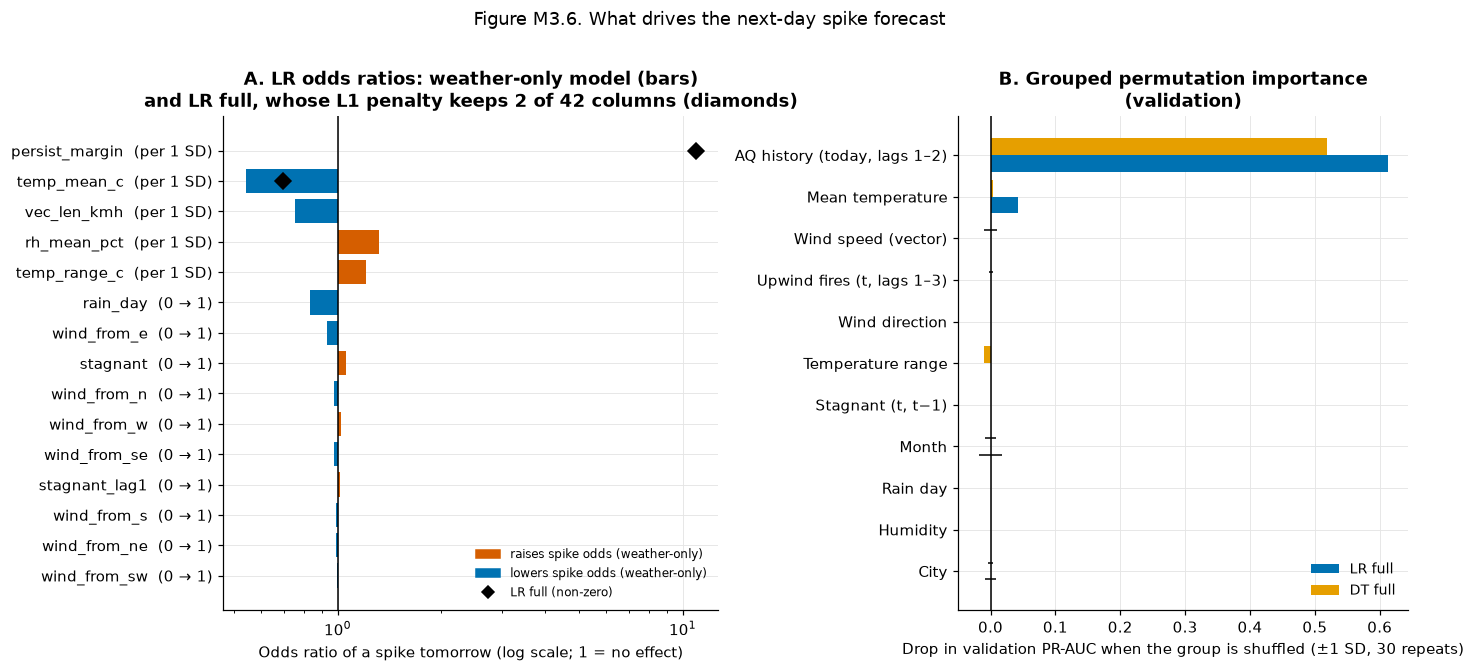

In [20]:
# Figure M3.6: drivers
fig, axes = plt.subplots(1, 2, figsize=(13, 6), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
wo = odds[(odds.feature_set == "weather_only") & ~odds.feature.str.startswith(("city_", "month_"))]
full_nz = odds[(odds.feature_set == "full") & (odds.coef != 0)].set_index("feature")
o = wo.assign(a=wo.coef.abs()).sort_values("a").tail(14)
o = pd.concat([o, odds[(odds.feature_set == "full") & odds.feature.isin(full_nz.index.difference(o.feature))]])
labels = o.feature + "  (" + o.scale + ")"
yy = np.arange(len(o))
wcoef = np.where(o.feature_set == "weather_only", o.coef, 0.0)
ax.barh(yy, np.exp(wcoef) - 1, left=1, color=[P.CAT_COLORS[1] if v > 0 else P.CAT_COLORS[0] for v in wcoef],
        label="_nolegend_")                                                          # bars run from OR = 1
for k, fname in enumerate(o.feature):
    if fname in full_nz.index:
        ax.plot(full_nz.loc[fname, "odds_ratio"], k, "D", color="#000000", ms=7)
ax.set_yticks(yy); ax.set_yticklabels(labels)
ax.set_xscale("log"); ax.axvline(1, color="#000000", lw=1)
ax.set_xlabel("Odds ratio of a spike tomorrow (log scale; 1 = no effect)")
ax.set_title("A. LR odds ratios: weather-only model (bars)\nand LR full, whose L1 penalty keeps 2 of 42 columns (diamonds)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=P.CAT_COLORS[1]), plt.Rectangle((0, 0), 1, 1, color=P.CAT_COLORS[0]),
                   Line2D([], [], marker="D", color="#000000", ls="none")],
          labels=["raises spike odds (weather-only)", "lowers spike odds (weather-only)", "LR full (non-zero)"],
          loc="lower right", fontsize=8)
ax = axes[1]
pi = importance[importance.method.str.startswith("permutation")].pivot(index="group", columns="model", values="mean")
pis = importance[importance.method.str.startswith("permutation")].pivot(index="group", columns="model", values="sd")
pi = pi.sort_values("LR full")
yy = np.arange(len(pi))
for k, (m, c) in enumerate([("LR full", COLOR["lr_full"]), ("DT full", P.CAT_COLORS[3])]):
    ax.barh(yy + (k - 0.5) * 0.4, pi[m], height=0.4, xerr=pis[m], color=c, label=m, error_kw={"lw": 1})
ax.set_yticks(yy); ax.set_yticklabels(pi.index)
ax.axvline(0, color="#000000", lw=1)
ax.set_xlabel("Drop in validation PR-AUC when the group is shuffled (±1 SD, 30 repeats)")
ax.set_title("B. Grouped permutation importance\n(validation)")
ax.legend(loc="lower right")
fig.suptitle("Figure M3.6. What drives the next-day spike forecast", y=1.01)
fig.tight_layout()
P.save(fig, "fig_m3_6_drivers")
plt.show()

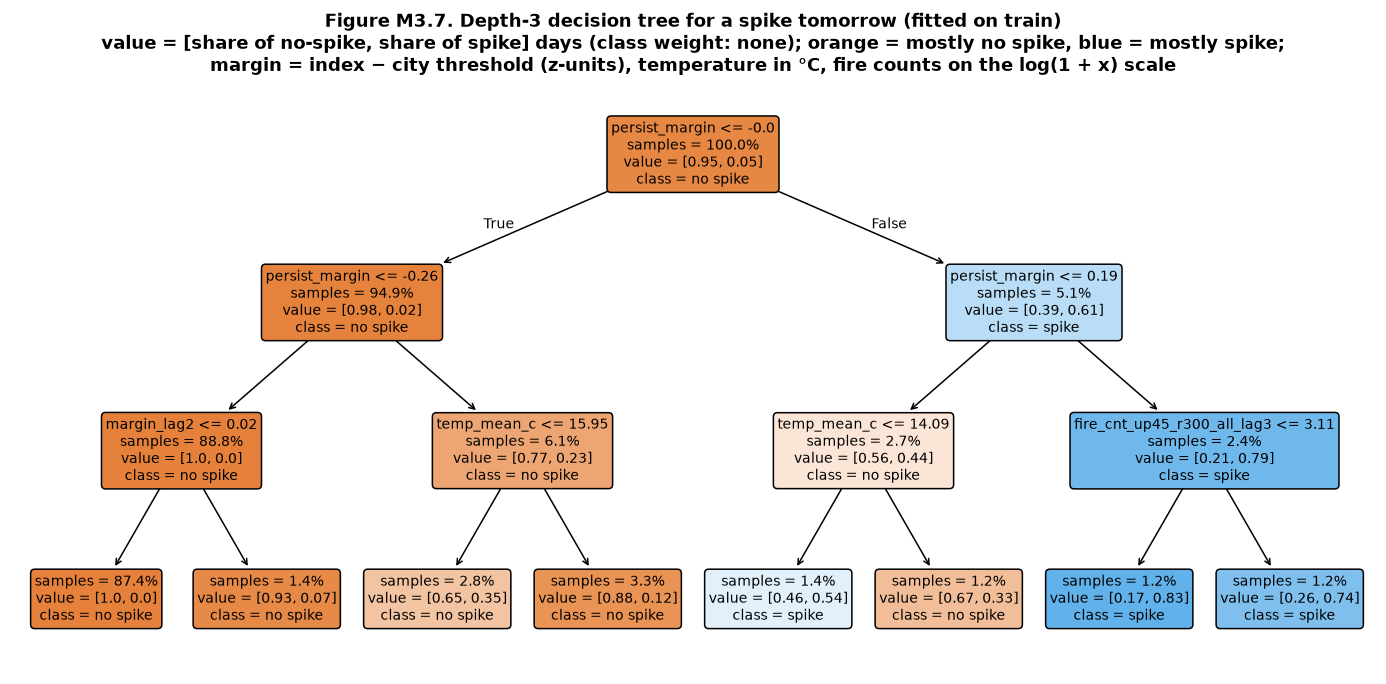

Depth-3 tree, validation PR-AUC 0.5638, ROC-AUC 0.9035


In [21]:
# Figure M3.7: a readable depth-3 tree (best leaf size and class weight of the tuned full tree, refitted on train)
from sklearn.tree import plot_tree

bp = searches["dt_full"].best_params_
small = MD.make_tree(MD.FEATURE_SETS["full"]).set_params(model__max_depth=3, model__min_samples_leaf=bp["model__min_samples_leaf"],
                                                         model__class_weight=bp["model__class_weight"])
assert_train_only(train)
small.fit(X_tr["full"], y_tr)
fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(small.named_steps["model"], feature_names=list(small.named_steps["prep"].get_feature_names_out()),
          class_names=["no spike", "spike"], filled=True, rounded=True, impurity=False, proportion=True,
          precision=2, fontsize=9, ax=ax)
ax.set_title("Figure M3.7. Depth-3 decision tree for a spike tomorrow (fitted on train)\n"
             f"value = [share of no-spike, share of spike] days (class weight: {bp['model__class_weight'] or 'none'}); "
             "orange = mostly no spike, blue = mostly spike;\nmargin = index − city threshold (z-units), temperature in °C, "
             "fire counts on the log(1 + x) scale")
P.save(fig, "fig_m3_7_tree")
plt.show()
p_small = small.predict_proba(X_va["full"])[:, 1]
print(f"Depth-3 tree, validation PR-AUC {average_precision_score(y_va, p_small):.4f}, "
      f"ROC-AUC {roc_auc_score(y_va, p_small):.4f}")

---
## M3.9 Sensitivity

**(a) Month-wise spike label (decision D3).** The Milestone 2 label (city P90 of training October to March days)
puts most spikes in the December–January fog season, while fires peak in October–November. A null fire effect on
that label could be an artefact of the label. The month-wise label marks a spike when tomorrow's index is at or above
the **city × month P90** of the training days (suspect days excluded), so every month has about 10% spikes and a
November fire-smoke episode counts as much as a December fog episode. The tuned hyperparameters are reused; the
models are refitted, new out-of-fold thresholds are chosen, and the folds are rebuilt (stratified on the new label).

**(b) Horizons h = 2 and 3 (decision D2).** Same tuned pipelines and the same procedure, with the purge and embargo
lengthened to the horizon.

**(c) AQ-history encoding.** The Phase 3 encoding (raw pooled index `persist_index`, `index_lag1`, `index_lag2`)
retuned on the same folds, to show what the margin encoding changes.

**(d) Regression of the continuous index.** Milestone 2 promised results for the continuous Composite Smog Index as
well (H5). A continuous target is a more sensitive test of the fire effect than a binary label.

In [22]:
def refit_and_score(tr, va, y_t, y_v, horizon, models=("lr_full", "lr_no_fire", "lr_weather_only",
                                                        "dt_full", "dt_no_fire", "dt_weather_only")):
    """Reuse the tuned h1 hyperparameters: OOF thresholds on train, refit on all train, score validation."""
    assert_train_only(tr)
    sp = MD.purged_sgkf_splits(tr, y_t, horizon=horizon)
    out = {}
    for m in models:
        s = m.split("_", 1)[1]
        est = searches[m].best_estimator_
        p_oof, folds = MD.oof_predict(est, tr[MD.FEATURE_SETS[s]], y_t, sp)
        thr, _ = MD.choose_threshold(y_t, p_oof, COST_FN, COST_FP)
        cvm = EV.cv_metrics(y_t, folds, threshold=thr)
        from sklearn.base import clone
        p_v = clone(est).fit(tr[MD.FEATURE_SETS[s]], y_t).predict_proba(va[MD.FEATURE_SETS[s]])[:, 1]
        out[m] = (cvm, EV.binary_metrics(y_v, p_v, threshold=thr))
    return out, sp


def persistence_cv(y_t, score_t, sp):
    """Persistence scored on the same purged folds (no threshold: the rule is fixed)."""
    return EV.cv_metrics(y_t, [(t, score_t[t]) for _, t in sp], yhat=(score_t >= 0).astype(int))


# City x month P90 of the daily index on training days (suspect days are already out of `train`)
thr_cm = (train.assign(month=train["date"].dt.month)
          .groupby(["city", "month"])["persist_index"].quantile(0.90).rename("thr_month"))
_ = save_table(thr_cm.unstack("month"), "m3_monthwise_thresholds")


def monthwise_label(d, horizon=1):
    tgt_month = (d["date"] + pd.Timedelta(days=horizon)).dt.month
    t_next = thr_cm.reindex(pd.MultiIndex.from_arrays([d["city"], tgt_month])).to_numpy()
    t_today = thr_cm.reindex(pd.MultiIndex.from_arrays([d["city"], d["date"].dt.month])).to_numpy()
    assert not np.isnan(t_next).any() and not np.isnan(t_today).any()
    return ((d[f"target_index_h{horizon}"] >= t_next).astype(int).to_numpy(),
            (d["persist_index"] - t_today).to_numpy())


ym_tr, pm_tr = monthwise_label(train)
ym_va, pm_va = monthwise_label(val)
res_m, sp_m = refit_and_score(train, val, ym_tr, ym_va, 1)
mw_rows = []
pers_m = (persistence_cv(ym_tr, pm_tr, sp_m), EV.binary_metrics(ym_va, pm_va, yhat=(pm_va >= 0).astype(int)))
for m, (cvm, vm) in [("persistence", pers_m)] + list(res_m.items()):
    mw_rows.append({"model": LABEL[m], "label": "month-wise P90",
                    "cv_pr_auc_mean": np.nan if cvm is None else cvm["pr_auc_mean"],
                    "cv_pr_auc_sd": np.nan if cvm is None else cvm["pr_auc_sd"],
                    **{f"val_{k}": vm[k] for k in ["pr_auc", "roc_auc", "recall", "precision", "f1", "cost_per_1000"]},
                    "val_spike_rate": ym_va.mean(), "train_spike_rate": ym_tr.mean()})
for m in ["persistence", "lr_full", "lr_no_fire", "lr_weather_only", "dt_full", "dt_no_fire", "dt_weather_only"]:
    vm = counts.loc[LABEL[m]]
    b = boot.loc[m, "estimate"]
    mw_rows.append({"model": LABEL[m], "label": "Milestone 2 (Oct–Mar P90)",
                    "cv_pr_auc_mean": metrics_cv.loc[LABEL[m], "pr_auc_mean"],
                    "cv_pr_auc_sd": metrics_cv.loc[LABEL[m], "pr_auc_sd"],
                    **{f"val_{k}": b[k] for k in ["pr_auc", "roc_auc", "recall", "precision", "f1", "cost_per_1000"]},
                    "val_spike_rate": y_va.mean(), "train_spike_rate": y_tr.mean()})
label_mw = pd.DataFrame(mw_rows)
_ = save_table(label_mw, "m3_label_monthwise", index=False)
print(label_mw.round(4).to_string(index=False))
print("\nMonth-wise label, spikes by month (train | validation):")
print(pd.concat([pd.Series(ym_tr).groupby((train["date"] + pd.Timedelta(days=1)).dt.month.values).mean().rename("train"),
                 pd.Series(ym_va).groupby((val["date"] + pd.Timedelta(days=1)).dt.month.values).mean().rename("validation")],
                axis=1).round(3).T.to_string())

          model                     label  cv_pr_auc_mean  cv_pr_auc_sd  val_pr_auc  val_roc_auc  val_recall  val_precision  val_f1  val_cost_per_1000  val_spike_rate  train_spike_rate
    Persistence            month-wise P90          0.3162        0.0327      0.4394       0.9458      0.4906         0.5098  0.5000           123.2666          0.0408             0.114
        LR full            month-wise P90          0.2540        0.0627      0.3486       0.9056      0.7925         0.2029  0.3231           169.4915          0.0408             0.114
     LR no-fire            month-wise P90          0.2531        0.0619      0.3308       0.9006      0.7925         0.1765  0.2887           193.3744          0.0408             0.114
LR weather-only            month-wise P90          0.1637        0.0363      0.0902       0.6501      0.6038         0.0605  0.1100           463.7904          0.0408             0.114
        DT full            month-wise P90          0.1952        0.0370    

**What we found (M3.9a): the month-wise label does not uncover a robust fire effect.**
- **The label.** It gives every training month about 10% to 13% spikes. Autumn 2023 was cleaner than autumn 2022: only 0.3% (September), 1.2% (October), 5.5% (November) and 8.8% (December) of validation days pass the 2022 city × month P90, 4.1% overall.
- **Persistence leads on this label.** Its validation PR-AUC is 0.439 (CV 0.316), against 0.349 for LR full (CV 0.254) and 0.247 for DT full (CV 0.195).
- **Fire: no robust gain.** LR no-fire scores 0.331 on validation (CV 0.253). The full model is 0.018 higher on validation, but only 0.001 higher in CV, and the two trees are identical on validation (0.247).
- **Interpretation.** At least with these features, the null fire result is not an artefact of the fog-season label: the October–November spikes the new label adds are no better predicted with fires than without.

In [23]:
hz_rows = []
for h in (1, 2, 3):
    if h == 1:
        for m in ["persistence"] + [k for k in MODELS if k.startswith(("lr", "dt"))]:
            b = boot.loc[m, "estimate"]
            hz_rows.append({"horizon": h, "model": LABEL[m],
                            "cv_pr_auc_mean": metrics_cv.loc[LABEL[m], "pr_auc_mean"],
                            **{f"val_{k}": b[k] for k in ["pr_auc", "roc_auc", "recall", "precision", "f1", "cost_per_1000"]},
                            "val_rows": len(val), "val_spikes": int(y_va.sum())})
        continue
    dfh, _ = MD.load_model_frame(h)
    trh = dfh[dfh.split == "train"].reset_index(drop=True); vah = dfh[dfh.split == "validation"].reset_index(drop=True)
    yth, yvh = trh[f"target_spike_h{h}"].to_numpy(), vah[f"target_spike_h{h}"].to_numpy()
    res_h, sp_h = refit_and_score(trh, vah, yth, yvh, h)
    s_p, yh_p = MD.persistence(vah)
    pm_h = EV.binary_metrics(yvh, s_p, yhat=yh_p)
    hz_rows.append({"horizon": h, "model": "Persistence",
                    "cv_pr_auc_mean": persistence_cv(yth, MD.persistence(trh)[0], sp_h)["pr_auc_mean"],
                    **{f"val_{k}": pm_h[k] for k in ["pr_auc", "roc_auc", "recall", "precision", "f1", "cost_per_1000"]},
                    "val_rows": len(vah), "val_spikes": int(yvh.sum())})
    for m, (cvm, vm) in res_h.items():
        hz_rows.append({"horizon": h, "model": LABEL[m], "cv_pr_auc_mean": cvm["pr_auc_mean"],
                        **{f"val_{k}": vm[k] for k in ["pr_auc", "roc_auc", "recall", "precision", "f1", "cost_per_1000"]},
                        "val_rows": len(vah), "val_spikes": int(yvh.sum())})
horizons = pd.DataFrame(hz_rows)
_ = save_table(horizons, "m3_horizons", index=False)
print(horizons.pivot(index="model", columns="horizon", values="val_pr_auc").loc[[LABEL[m] for m in MODELS[1:]]].round(4).to_string())
print()
print(horizons.round(4).to_string(index=False))

horizon               1       2       3
model                                  
Persistence      0.6687  0.5530  0.4448
LR full          0.6946  0.5966  0.4862
LR weather-only  0.3879  0.4034  0.3660
LR no-fire       0.6946  0.5966  0.4862
DT full          0.5895  0.4682  0.3721
DT weather-only  0.2256  0.2352  0.2139
DT no-fire       0.5854  0.4640  0.3721

 horizon           model  cv_pr_auc_mean  val_pr_auc  val_roc_auc  val_recall  val_precision  val_f1  val_cost_per_1000  val_rows  val_spikes
       1     Persistence          0.6362      0.6687       0.9629      0.6180         0.6875  0.6509           150.2311      1298          89
       1         LR full          0.6508      0.6946       0.9665      0.8652         0.4556  0.5969           117.1032      1298          89
       1 LR weather-only          0.4319      0.3879       0.8548      0.7640         0.2282  0.3514           258.0894      1298          89
       1      LR no-fire          0.6507      0.6946       0.9665      

**What we found (M3.9b).**
- **All skill fades with the horizon.** Validation PR-AUC for persistence falls from 0.669 (h1) to 0.553 (h2) and 0.445 (h3).
- **LR stays slightly ahead of persistence at every horizon.** LR full scores 0.695, 0.597 and 0.486 on validation. CV agrees, by small margins: 0.453 against 0.447 at h2, and 0.383 against 0.375 at h3.
- **Fire never helps at any horizon.** LR no-fire is equal to LR full on validation, and within 0.002 of it in CV.
- **Trees.** DT full stays below persistence (0.468 at h2, 0.372 at h3). At h3 the weather-only tree issues no alerts on validation (recall 0), because its out-of-fold threshold sits above every validation score.
- **Next step.** The h2 and h3 models reuse the h1 hyperparameters. Tuning per horizon is a Milestone 4 item.

### M3.9c AQ-history encoding: threshold margin (headline) vs raw index

LR and DT are retuned on `MD.FULL_RAW` (the full set with the raw index in place of the margins) with the same
grids and the same 25 purged folds; the thresholds come from the out-of-fold predictions as before. For the LR,
the change is close to a re-parametrisation: the threshold is constant within a city, so `margin = index −
threshold` spans the same columns as `index` plus the city dummies, and only the regularisation and the meaning of
the city coefficients change. For the tree it changes the split variable itself.

In [24]:
import json as _json

assert_train_only(train)
enc_rows = []


def max_city_or(pipe):
    names = list(pipe.named_steps["prep"].get_feature_names_out())
    coef = pipe.named_steps["model"].coef_[0]
    c = np.array([coef[names.index(n)] for n in MD.CITY_DUMMIES])
    if not c.any():
        return 1.0, "none (all city coefficients 0)"
    return float(np.exp(np.abs(c).max())), MD.CITY_DUMMIES[int(np.abs(c).argmax())]


for fam, make, grid in [("lr", MD.make_lr, MD.LR_GRID), ("dt", MD.make_tree, MD.DT_GRID)]:
    gs = MD.tune(make(MD.FULL_RAW), grid, train[MD.FULL_RAW], y_tr, splits)
    p_oof_raw, _ = MD.oof_predict(gs.best_estimator_, train[MD.FULL_RAW], y_tr, splits)
    thr_raw, _ = MD.choose_threshold(y_tr, p_oof_raw, COST_FN, COST_FP)
    p_va_raw = gs.best_estimator_.predict_proba(val[MD.FULL_RAW])[:, 1]
    for enc, est, cv_score, thr, p_v in [
            ("threshold margin (headline)", fitted[f"{fam}_full"], searches[f"{fam}_full"].best_score_,
             thresholds[f"{fam}_full"], score_va[f"{fam}_full"]),
            ("raw index (Phase 3)", gs.best_estimator_, gs.best_score_, thr_raw, p_va_raw)]:
        vm = EV.binary_metrics(y_va, p_v, threshold=thr)
        bp = (searches[f"{fam}_full"] if enc.startswith("threshold") else gs).best_params_
        or_max, or_city = max_city_or(est) if fam == "lr" else (np.nan, "")
        enc_rows.append({"encoding": enc, "model": LABEL[f"{fam}_full"],
                         "best_params": _json.dumps({k.replace("model__", ""): v for k, v in bp.items()}, default=float),
                         "cv_pr_auc": cv_score, "threshold": thr,
                         **{f"val_{k}": vm[k] for k in ["pr_auc", "roc_auc", "recall", "precision", "cost_per_1000"]},
                         "lr_max_city_or": or_max, "lr_max_city": or_city})
aq_encoding = pd.DataFrame(enc_rows)
_ = save_table(aq_encoding, "m3_aq_encoding", index=False)
print(aq_encoding.round(4).to_string(index=False))

                   encoding   model                                                          best_params  cv_pr_auc  threshold  val_pr_auc  val_roc_auc  val_recall  val_precision  val_cost_per_1000  lr_max_city_or                    lr_max_city
threshold margin (headline) LR full    {"C": 0.02682695795279726, "class_weight": null, "l1_ratio": 1.0}     0.6508     0.1280      0.6946       0.9665      0.8652         0.4556           117.1032          1.0000 none (all city coefficients 0)
        raw index (Phase 3) LR full                  {"C": 100.0, "class_weight": null, "l1_ratio": 0.0}     0.6048     0.1000      0.6338       0.9607      0.8315         0.4458           128.6595       9003.9299            city_rahim_yar_khan
threshold margin (headline) DT full       {"class_weight": null, "max_depth": 4, "min_samples_leaf": 50}     0.5190     0.1988      0.5895       0.9531      0.8202         0.5214           113.2512             NaN                               
        raw index (P

**What we found (M3.9c): the margin encoding fixes the city odds ratios and helps both models.**
- **LR.** With the raw index, LR full tunes to C = 100 (L2): CV PR-AUC 0.605, validation 0.634, cost at 5:1 128.7 per 1,000 (margin: 117.1). Its city odds ratios reach **9,004** (Rahim Yar Khan against Lahore). With the margin, the strongly penalised L1 model (C = 0.027) scores CV 0.651 and validation 0.695, and every city coefficient is 0. With the raw index, the model had to stay weakly regularised so that the city dummies could carry large threshold corrections. The margin makes those corrections unnecessary.
- **DT.** The tree gains most: CV 0.350 → 0.519, validation 0.373 → 0.590, cost at 5:1 228.8 → 113.3. A single split on the margin replaces what the raw-index tree had to rebuild from city × index splits.
- **Not a choice made on results.** The margin was fixed as the headline before this comparison was run. The Phase 3 numbers stay reproducible here.

### M3.9d Regression of the continuous next-day index (Ridge)

`Ridge` on `target_index_h1` for the three feature sets, with the LR preprocessing. Alpha (11 values from 0.01 to
1,000) is tuned on the same 25 purged folds by mean absolute error (MAE). The benchmark is persistence
(tomorrow's index = today's, `persist_index`). We report CV (mean ± SD over the folds) and validation MAE, RMSE
and R², with 95% week-block bootstrap CIs on validation, and paired bootstrap differences in MAE (negative = the
first model is better).

In [25]:
yi_tr, yi_va = train["target_index_h1"].to_numpy(), val["target_index_h1"].to_numpy()
assert not np.isnan(yi_tr).any() and not np.isnan(yi_va).any()
assert_train_only(train)
RG = {"persistence": "Persistence (index)", **{f"ridge_{s}": f"Ridge {SET_LABEL[s]}" for s in SETS}}
ridge_cv, ridge_alpha, pred_va_r = {}, {}, {"persistence": val["persist_index"].to_numpy()}
ridge_cv["persistence"] = [(t, train["persist_index"].to_numpy()[t]) for _, t in splits]
for s in SETS:
    gs = MD.tune(MD.make_ridge(MD.FEATURE_SETS[s]), MD.RIDGE_GRID, X_tr[s], yi_tr, splits,
                 scoring="neg_mean_absolute_error")
    ridge_alpha[f"ridge_{s}"] = float(gs.best_params_["model__alpha"])
    _, ridge_cv[f"ridge_{s}"] = MD.oof_predict(gs.best_estimator_, X_tr[s], yi_tr, splits, method="predict")
    pred_va_r[f"ridge_{s}"] = gs.best_estimator_.predict(X_va[s])
    fitted[f"ridge_{s}"] = gs.best_estimator_

R_PAIRS = [("ridge_full", "ridge_no_fire"), ("ridge_no_fire", "ridge_weather_only"),
           ("ridge_full", "persistence"), ("ridge_no_fire", "persistence"), ("ridge_weather_only", "persistence")]
rframe = val[["city", "date", "target_index_h1"]].copy()
for m, p in pred_va_r.items():
    rframe[f"r_{m}"] = p


def reg_all(d):
    out = {}
    for m in RG:
        out.update({f"{m}|{k}": v for k, v in EV.regression_metrics(d["target_index_h1"], d[f"r_{m}"]).items()})
    for a, b in R_PAIRS:
        out[f"{a}|{b}"] = (EV.regression_metrics(d["target_index_h1"], d[f"r_{a}"])["mae"]
                           - EV.regression_metrics(d["target_index_h1"], d[f"r_{b}"])["mae"])
    return out


rb = EV.block_bootstrap(rframe, reg_all, n=N_BOOT, seed=42)
reg_rows = []
for m in RG:
    cvm = pd.DataFrame([EV.regression_metrics(yi_tr[t], p) for t, p in ridge_cv[m]])
    for k in ["mae", "rmse", "r2"]:
        r = rb.loc[f"{m}|{k}"]
        reg_rows.append({"kind": "model", "name": RG[m], "metric": k, "alpha": ridge_alpha.get(m, np.nan),
                         "cv_mean": cvm[k].mean(), "cv_sd": cvm[k].std(),
                         "validation": r.estimate, "ci_low": r.ci_low, "ci_high": r.ci_high})
for a, b in R_PAIRS:
    d_cv = np.array([EV.regression_metrics(yi_tr[t], pa)["mae"] - EV.regression_metrics(yi_tr[t], pb)["mae"]
                     for (t, pa), (_, pb) in zip(ridge_cv[a], ridge_cv[b])])
    r = rb.loc[f"{a}|{b}"]
    reg_rows.append({"kind": "difference", "name": f"{RG[a]} − {RG[b]}", "metric": "mae",
                     "cv_mean": d_cv.mean(), "cv_sd": d_cv.std(ddof=1), "cv_folds_a_better": int((d_cv < 0).sum()),
                     "validation": r.estimate, "ci_low": r.ci_low, "ci_high": r.ci_high,
                     "ci_excludes_0": bool(r.ci_low > 0 or r.ci_high < 0)})
index_reg = pd.DataFrame(reg_rows)
_ = save_table(index_reg, "m3_index_regression", index=False)
print(index_reg.round(4).to_string(index=False))

      kind                                     name metric  alpha  cv_mean  cv_sd  validation  ci_low  ci_high  cv_folds_a_better ci_excludes_0
     model                      Persistence (index)    mae    NaN   0.2908 0.0143      0.2741  0.2473   0.3009                NaN           NaN
     model                      Persistence (index)   rmse    NaN   0.3806 0.0191      0.3502  0.3171   0.3854                NaN           NaN
     model                      Persistence (index)     r2    NaN   0.7217 0.0481      0.7846  0.7007   0.8260                NaN           NaN
     model                               Ridge full    mae 0.3162   0.2773 0.0089      0.2874  0.2596   0.3147                NaN           NaN
     model                               Ridge full   rmse 0.3162   0.3562 0.0159      0.3613  0.3295   0.3926                NaN           NaN
     model                               Ridge full     r2 0.3162   0.7574 0.0338      0.7708  0.6858   0.8104                NaN       

**What we found (M3.9d): the continuous index gives the same answers.**
- **Persistence is hard to beat on the index.** On validation, persistence has an MAE of **0.274** [0.247, 0.301] and an R² of 0.785. Ridge full (alpha = 0.32) has an MAE of 0.287 [0.260, 0.315] and an R² of 0.771. Its ΔMAE against persistence is **+0.013** [−0.004, +0.034] (worse, but not significantly).
- **CV is slightly kinder to Ridge.** Ridge full has a CV MAE of 0.277 ± 0.009, against 0.291 for persistence, and is better in 22 of 25 folds. The validation season's long December episodes favour persistence (as in M3.4).
- **Fire adds nothing to the index forecast either.** Ridge full minus Ridge no-fire is ΔMAE −0.001 [−0.003, +0.001] on validation, and +0.0002 in CV (full better in 14 of 25 folds). The continuous target was the more sensitive test, and it confirms the null.
- **Weather alone is far worse.** Ridge weather-only has an MAE of 0.532 and an R² of 0.23. Removing AQ history costs 0.243 MAE [0.202, 0.291].
- **H5 for the index.** No model beats persistence on validation MAE, so H5's null is not rejected for the continuous index (ΔMAE ≥ 0). The spike forecasts gain a little in ranking (M3.5) and a lot in alert cost (M3.6).

---
## M3.10 Model artifacts

The tuned pipelines (refitted on all training rows, h = 1; the three Ridge index models of M3.9d included) are saved with `joblib` to `models/`, and the tuned
hyperparameters and thresholds to `Dataset/clean/m3_params.json`. Load one with `joblib.load("models/lr_full.joblib")`
and call `predict_proba` on a frame with the columns of `src.modeling.FEATURE_SETS[...]`.

In [26]:
import joblib
import platform
import sklearn
import statsmodels

Path("models").mkdir(exist_ok=True)
for m, est in fitted.items():
    joblib.dump(est, f"models/{m}.joblib")
print("Saved:", sorted(p.name for p in Path("models").glob("*.joblib")))
print(f"Python {platform.python_version()}, numpy {np.__version__}, pandas {pd.__version__}, "
      f"scikit-learn {sklearn.__version__}, statsmodels {statsmodels.__version__}, joblib {joblib.__version__}")
print(f"Total run time: {time.time() - T0:.0f} s")

Saved: ['dt_full.joblib', 'dt_no_fire.joblib', 'dt_weather_only.joblib', 'lr_full.joblib', 'lr_no_fire.joblib', 'lr_weather_only.joblib', 'majority.joblib', 'ridge_full.joblib', 'ridge_no_fire.joblib', 'ridge_weather_only.joblib']
Python 3.14.6, numpy 2.5.4, pandas 3.1.0, scikit-learn 1.9.1, statsmodels 0.15.0, joblib 1.6.0
Total run time: 281 s
